In [1]:
from pathlib import Path

print("Notebook folder:", Path.cwd())
print("Data files:", [
    p.name for p in Path.cwd().iterdir()
    if p.suffix.lower() in {".csv",".zip", ".xlsx", ".xls"}
])

Notebook folder: /Users/emmyli/Downloads/BT4211 Marketing/final proj
Data files: ['spotify_dataset.csv']


In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

sheets = pd.read_csv("spotify_dataset.csv")

print("Sheets and sizes:", {name: sheet.shape for name, sheet in sheets.items()})


Sheets and sizes: {'Unnamed: 0': (114000,), 'track_id': (114000,), 'artists': (114000,), 'album_name': (114000,), 'track_name': (114000,), 'popularity': (114000,), 'duration_ms': (114000,), 'explicit': (114000,), 'danceability': (114000,), 'energy': (114000,), 'key': (114000,), 'loudness': (114000,), 'mode': (114000,), 'speechiness': (114000,), 'acousticness': (114000,), 'instrumentalness': (114000,), 'liveness': (114000,), 'valence': (114000,), 'tempo': (114000,), 'time_signature': (114000,), 'track_genre': (114000,)}


In [4]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_path = Path.cwd() / "spotify_dataset.csv"
print(f"Notebook current folder: {Path.cwd()}")
print(f"CSV path: {csv_path}")
print(f"File exists: {csv_path.is_file()}")

raw_df = None
audit_df = None
if not csv_path.is_file():
    print("Could not load the dataset because spotify_dataset.csv is not in the notebook's current folder.")
    print("Fix: place the file in the folder shown above, or update csv_path to its actual location.")
else:
    try:
        # Use pandas defaults; do not guess an encoding or delimiter.
        raw_df = pd.read_csv(csv_path)
    except Exception as exc:
        print(f"CSV load failed: {type(exc).__name__}: {exc}")
        print("Fix: verify the file is a valid CSV and confirm its encoding and delimiter from its source; then set the appropriate read_csv options explicitly.")

if raw_df is not None:
    print(f"\nRows: {raw_df.shape[0]:,}")
    print(f"Columns: {raw_df.shape[1]:,}")
    print("\nColumn names and data types:")
    display(pd.DataFrame({"column": raw_df.columns, "dtype": raw_df.dtypes.astype(str).values}))
    print("\nFirst five rows:")
    display(raw_df.head())

    row_count = len(raw_df)
    index_like = [
        col for col in raw_df.columns
        if str(col).strip().lower() == "index"
        or str(col).strip().lower().startswith("unnamed:")
    ]
    sequential_columns = []
    for col in raw_df.columns:
        numeric_values = pd.to_numeric(raw_df[col], errors="coerce")
        sequential_zero = numeric_values.notna().all() and numeric_values.reset_index(drop=True).tolist() == list(range(row_count))
        sequential_one = numeric_values.notna().all() and numeric_values.reset_index(drop=True).tolist() == list(range(1, row_count + 1))
        if sequential_zero or sequential_one:
            sequential_columns.append(col)

    print("\nExported-index review:")
    if index_like:
        for col in index_like:
            print(f"- {col!r}: appears index-like by name; sequential 0..{row_count - 1} or 1..{row_count}: {col in sequential_columns}")
    else:
        print("- No columns named like an exported index (e.g. 'Unnamed: 0' or 'index').")
    other_sequential = [col for col in sequential_columns if col not in index_like]
    if other_sequential:
        print(f"- Other columns exactly sequential from 0 or 1: {other_sequential}")
    if not index_like and not other_sequential:
        print("- No sequential index-like columns identified.")
    print("No columns have been dropped or altered.")

Notebook current folder: /Users/emmyli/Downloads/BT4211 Marketing/final proj
CSV path: /Users/emmyli/Downloads/BT4211 Marketing/final proj/spotify_dataset.csv
File exists: True

Rows: 114,000
Columns: 21

Column names and data types:


,column,dtype
0,Unnamed: 0,int64
1,track_id,object
2,artists,object
3,album_name,object
4,track_name,object
5,popularity,int64
6,duration_ms,int64
7,explicit,bool
8,danceability,float64
9,energy,float64



First five rows:


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic



Exported-index review:
- 'Unnamed: 0': appears index-like by name; sequential 0..113999 or 1..114000: True
No columns have been dropped or altered.


In [5]:
if raw_df is None:
    print("Audit checks were not run because the CSV did not load. See the load error or missing-file message above.")
else:
    # Normalize blank text only on a deep copy; raw_df remains unchanged.
    audit_df = raw_df.copy(deep=True)
    audit_df = audit_df.replace(r"^\s*$", pd.NA, regex=True)
    print(f"audit_df created as a separate copy: {audit_df.shape}; raw_df is unchanged.")

    missing_table = pd.DataFrame({
        "missing_count": audit_df.isna().sum(),
        "missing_percent": (audit_df.isna().mean() * 100).round(2),
    })
    print("\nMissing values by column (blank/whitespace-only text treated as missing in audit_df):")
    display(missing_table)
    rows_with_missing = int(audit_df.isna().any(axis=1).sum())
    print(f"Rows with at least one missing value: {rows_with_missing:,} of {len(audit_df):,}")

    duplicate_after_first = audit_df.duplicated()
    duplicate_group_members = audit_df.duplicated(keep=False)
    print("\nExact duplicate rows across all columns:")
    print(f"Rows duplicated after the first copy (duplicated()): {int(duplicate_after_first.sum()):,}")
    print(f"All rows belonging to duplicate groups (duplicated(keep=False)): {int(duplicate_group_members.sum()):,}")
    if duplicate_group_members.any():
        print("All rows belonging to exact-duplicate groups:")
        display(audit_df.loc[duplicate_group_members])
    else:
        print("No exact duplicate groups found.")

    repeated_id_count = 0
    repeated_id_rows = 0
    multi_genre_ids = 0
    conflict_counts = {}
    conflict_examples = []
    audio_feature_cols = [
        "danceability", "energy", "speechiness", "acousticness",
        "instrumentalness", "liveness", "valence",
    ]
    conflict_value_cols = [
        col for col in ["popularity", *audio_feature_cols]
        if col in audit_df.columns
    ]
    if "track_id" in audit_df.columns:
        id_counts = audit_df["track_id"].value_counts(dropna=True)
        repeated_ids = id_counts[id_counts > 1]
        repeated_id_count = len(repeated_ids)
        repeated_id_rows = int(audit_df["track_id"].isin(repeated_ids.index).sum())
        print("\nRepeated track_id values:")
        print(f"Distinct track_id values repeated: {repeated_id_count:,}")
        print(f"Rows carrying those repeated IDs: {repeated_id_rows:,}")

        for col in conflict_value_cols:
            conflict_counts[col] = 0
        for track_id, group in audit_df.loc[audit_df["track_id"].isin(repeated_ids.index)].groupby("track_id", sort=False):
            genres = []
            if "track_genre" in group.columns:
                genres = group["track_genre"].dropna().unique().tolist()
                if len(genres) > 1:
                    multi_genre_ids += 1
            conflicting_cols = []
            for col in conflict_value_cols:
                if group[col].nunique(dropna=True) > 1:
                    conflict_counts[col] += 1
                    conflicting_cols.append(col)
            if len(genres) > 1 or conflicting_cols:
                conflict_examples.append({
                    "track_id": track_id,
                    "rows": len(group),
                    "genres": genres,
                    "conflicting_popularity/audio_features": conflicting_cols,
                })
        if "track_genre" in audit_df.columns:
            print(f"Repeated IDs with multiple non-missing track_genre values: {multi_genre_ids:,}")
        else:
            print("Genre comparison not completed: track_genre column is absent.")
        print("Repeated IDs with conflicting non-missing popularity/audio-feature values by column:")
        display(pd.Series(conflict_counts, name="repeated_IDs_with_conflicts", dtype="int64").to_frame())
        print("Up to 10 repeated-ID examples with multiple genres and/or conflicting values:")
        display(pd.DataFrame(conflict_examples[:10]))
        if not repeated_id_count:
            print("No repeated non-missing track_id values found.")
    else:
        print("\nRepeated track_id check not completed: track_id column is absent.")

    print("\nBasic structure:")
    if "track_genre" in audit_df.columns:
        genre_count = int(audit_df["track_genre"].nunique(dropna=True))
        print(f"Unique non-missing genres: {genre_count:,}")
        print("Rows per genre (including missing genre labels if present):")
        display(audit_df["track_genre"].value_counts(dropna=False).rename_axis("track_genre").to_frame("rows"))
    else:
        genre_count = None
        print("Genre summary not completed: track_genre column is absent.")
    if "artists" in audit_df.columns:
        artist_count = int(audit_df["artists"].nunique(dropna=True))
        print(f"Unique non-missing artists: {artist_count:,}")
    else:
        artist_count = None
        print("Artist count not completed: artists column is absent.")
    row_count = len(audit_df)
    approximate_114k = abs(row_count - 114_000) <= 1_140
    print(f"Actual row count: {row_count:,}; approximately 114,000 (within 1%): {approximate_114k} (difference: {row_count - 114_000:+,}).")

    def numeric_review(column, lower=None, upper=None, allowed_values=None, positive=False):
        series = audit_df[column]
        numeric = pd.to_numeric(series, errors="coerce")
        nonnumeric = series.notna() & numeric.isna()
        valid = numeric.dropna()
        result = {
            "column": column,
            "dtype": str(series.dtype),
            "minimum": valid.min() if not valid.empty else pd.NA,
            "maximum": valid.max() if not valid.empty else pd.NA,
            "non_numeric_count": int(nonnumeric.sum()),
            "non_numeric_examples": series[nonnumeric].astype(str).unique().tolist()[:10],
        }
        if lower is not None or upper is not None:
            out_of_range = pd.Series(False, index=series.index)
            if lower is not None:
                out_of_range |= numeric < lower
            if upper is not None:
                out_of_range |= numeric > upper
            result["out_of_range_count"] = int(out_of_range.sum())
            result["out_of_range_examples"] = numeric[out_of_range].dropna().unique().tolist()[:10]
        if allowed_values is not None:
            unusual = numeric.notna() & ~numeric.isin(allowed_values)
            result["unusual_count"] = int(unusual.sum())
            result["unusual_examples"] = numeric[unusual].unique().tolist()[:10]
        if positive:
            unusual = numeric.notna() & (numeric <= 0)
            result["nonpositive_count"] = int(unusual.sum())
            result["nonpositive_examples"] = numeric[unusual].unique().tolist()[:10]
        return result

    print("\nPlausible-value checks (values are reported for review; nothing is changed):")
    required_value_columns = [
        "popularity", "duration_ms", *audio_feature_cols,
        "key", "mode", "time_signature", "tempo", "loudness", "explicit",
    ]
    absent_columns = [col for col in required_value_columns if col not in audit_df.columns]
    if absent_columns:
        print(f"Checks not completed because columns are absent: {absent_columns}")

    if "popularity" in audit_df.columns:
        popularity_review = numeric_review("popularity", lower=0, upper=100)
        print(f"popularity: dtype={popularity_review['dtype']}; outside 0-100 count={popularity_review['out_of_range_count']}; examples={popularity_review['out_of_range_examples']}; non-numeric count={popularity_review['non_numeric_count']}; examples={popularity_review['non_numeric_examples']}")
    if "duration_ms" in audit_df.columns:
        duration_review = numeric_review("duration_ms")
        duration_numeric = pd.to_numeric(audit_df["duration_ms"], errors="coerce")
        invalid_duration = duration_numeric.notna() & (duration_numeric <= 0)
        print(f"duration_ms: dtype={duration_review['dtype']}; zero/negative count={int(invalid_duration.sum())}; examples={duration_numeric[invalid_duration].unique().tolist()[:10]}; non-numeric count={duration_review['non_numeric_count']}; examples={duration_review['non_numeric_examples']}")
    for col in audio_feature_cols:
        if col in audit_df.columns:
            feature_review = numeric_review(col, lower=0, upper=1)
            print(f"{col}: outside 0-1 count={feature_review['out_of_range_count']}; examples={feature_review['out_of_range_examples']}; non-numeric count={feature_review['non_numeric_count']}; examples={feature_review['non_numeric_examples']}")

    domain_notes = {
        "key": "review values outside the common 0-11 range",
        "mode": "review values outside {0, 1}",
        "time_signature": "review values outside the common 3-7 range",
        "tempo": "review non-positive values",
        "loudness": "review the reported extremes; no cutoff is imposed",
    }
    for col in ["key", "mode", "time_signature", "tempo", "loudness"]:
        if col not in audit_df.columns:
            continue
        if col == "mode":
            review = numeric_review(col, allowed_values=[0, 1])
        elif col == "key":
            review = numeric_review(col, lower=0, upper=11)
        elif col == "time_signature":
            review = numeric_review(col, lower=3, upper=7)
        elif col == "tempo":
            review = numeric_review(col, positive=True)
        else:
            review = numeric_review(col)
        print(f"{col}: min={review['minimum']}; max={review['maximum']}; non-numeric count={review['non_numeric_count']}; examples={review['non_numeric_examples']}; {domain_notes[col]}.")
        if "out_of_range_count" in review:
            print(f"  Outside common range count={review['out_of_range_count']}; examples={review['out_of_range_examples']}")
        if "unusual_count" in review:
            print(f"  Not in {0, 1} count={review['unusual_count']}; examples={review['unusual_examples']}")
        if "nonpositive_count" in review:
            print(f"  Non-positive count={review['nonpositive_count']}; examples={review['nonpositive_examples']}")

    if "explicit" in audit_df.columns:
        explicit = audit_df["explicit"]
        explicit_values = explicit.dropna().unique().tolist()
        print(f"explicit: dtype={explicit.dtype}; unique non-missing values={explicit_values}; missing count={int(explicit.isna().sum())}")

    absent_structure = [col for col in ["track_id", "track_genre", "artists"] if col not in audit_df.columns]
    print("\nConcise audit summary:")
    print(f"- {row_count:,} rows x {audit_df.shape[1]:,} columns; approximately 114,000 rows within 1%: {approximate_114k}.")
    print(f"- {rows_with_missing:,} rows have at least one missing value after blank-text checks in audit_df.")
    print(f"- Exact duplicate rows after first copy: {int(duplicate_after_first.sum()):,}; all duplicate-group rows: {int(duplicate_group_members.sum()):,}.")
    if "track_id" in audit_df.columns:
        print(f"- Repeated track IDs: {repeated_id_count:,} distinct IDs across {repeated_id_rows:,} rows; no IDs were removed.")
    if "track_genre" in audit_df.columns:
        print(f"- Unique genres: {genre_count:,}.")
    if "artists" in audit_df.columns:
        print(f"- Unique artists: {artist_count:,}.")
    if absent_columns or absent_structure:
        print(f"- Checks not completed due to absent columns: {sorted(set(absent_columns + absent_structure))}.")
    else:
        print("- All requested check columns were present.")
    print("- This was an audit only: raw_df was not modified; no rows were dropped and no values were imputed or cleaned.")

audit_df created as a separate copy: (114000, 21); raw_df is unchanged.

Missing values by column (blank/whitespace-only text treated as missing in audit_df):


,missing_count,missing_percent
Unnamed: 0,0,0.0
track_id,0,0.0
artists,1,0.0
album_name,1,0.0
track_name,1,0.0
popularity,0,0.0
duration_ms,0,0.0
explicit,0,0.0
danceability,0,0.0
energy,0,0.0


Rows with at least one missing value: 1 of 114,000

Exact duplicate rows across all columns:
Rows duplicated after the first copy (duplicated()): 0
All rows belonging to duplicate groups (duplicated(keep=False)): 0
No exact duplicate groups found.

Repeated track_id values:
Distinct track_id values repeated: 16,641
Rows carrying those repeated IDs: 40,900


Repeated IDs with multiple non-missing track_genre values: 16,299
Repeated IDs with conflicting non-missing popularity/audio-feature values by column:


,repeated_IDs_with_conflicts
popularity,720
danceability,0
energy,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0


Up to 10 repeated-ID examples with multiple genres and/or conflicting values:


,track_id,rows,genres,conflicting_popularity/audio_features
0,5SuOikwiRyPMVoIQDJUgSV,4,"[acoustic, j-pop, singer-songwriter, songwriter]",[]
1,4qPNDBW1i3p13qLCt0Ki3A,2,"[acoustic, chill]",[]
2,01MVOl9KtVTNfFiBU9I7dc,2,"[acoustic, indie-pop]",[]
3,6Vc5wAMmXdKIAM7WUoEb7N,2,"[acoustic, piano]",[]
4,1EzrEOXmMH3G43AXT1y7pA,2,"[acoustic, rock]",[]
5,7k9GuJYLp2AzqokyEdwEw2,2,"[acoustic, piano]",[]
6,4ptDJbJl35d7gQfeNteBwp,2,"[acoustic, chill]",[]
7,0X9MxHR1rTkEHDjp95F2OO,2,"[acoustic, chill]",[]
8,6xKeQgzfjixSUld14qUezm,2,"[acoustic, guitar]",[]
9,4Yo0igmcoNyat1secaH0OD,2,"[acoustic, guitar]",[]



Basic structure:
Unique non-missing genres: 114
Rows per genre (including missing genre labels if present):


,rows
track_genre,
acoustic,1000
punk-rock,1000
progressive-house,1000
power-pop,1000
pop,1000
...,...
folk,1000
emo,1000
electronic,1000


Unique non-missing artists: 31,437
Actual row count: 114,000; approximately 114,000 (within 1%): True (difference: +0).

Plausible-value checks (values are reported for review; nothing is changed):
popularity: dtype=int64; outside 0-100 count=0; examples=[]; non-numeric count=0; examples=[]
duration_ms: dtype=int64; zero/negative count=1; examples=[0]; non-numeric count=0; examples=[]
danceability: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
energy: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
speechiness: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
acousticness: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
instrumentalness: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
liveness: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
valence: outside 0-1 count=0; examples=[]; non-numeric count=0; examples=[]
key: min=0; max=11; non-numeric count=0; examples=[]; rev

<!-- cleaning-eda-start -->
# Part 2 - Data cleaning

The audit above only *reports* problems; `raw_df` was never changed. So the cleaning is **not complete yet**.
The audit found these problems, and each one is handled below:

| # | Issue found in audit | Rows | Decision |
|---|---|---|---|
| 1 | `Unnamed: 0` is an exported row index (0..113999) | all | Drop the column |
| 2 | One row has no `artists` / `album_name` / `track_name` **and** `duration_ms = 0` | 1 | Drop the row (no usable identity, impossible duration) |
| 3 | `tempo = 0` (all of them also have `danceability = 0`, `speechiness = 0`, `time_signature = 0`). These are mostly `sleep` / white-noise tracks | 157 | Keep the rows, but set `tempo` to NaN because tempo is undefined for them. Flag them as `non_music` |
| 4 | `time_signature = 0` is not a real meter | 163 | Set to NaN. Keep `time_signature = 1` (Spotify uses it for free or irregular meter) |
| 5 | The same `track_id` appears under several genres (one row per genre label) | 24,259 extra rows | Build two tables: `genre_df` (one row per track x genre, used for genre analysis) and `tracks` (one row per song, used for everything else) |
| 6 | The same `track_id` has conflicting `popularity` across its genre rows | 720 IDs | Use the max popularity for that ID |
| 7 | The same song (same `artists` + `track_name`) is re-released under a different `track_id` (album vs. single vs. compilation). Many copies are popularity-0 "shadow" releases | ~8.4k extra songs | In `tracks`, keep the most popular release of each song |
| 8 | Text fields with leading/trailing whitespace | 8 | Strip whitespace |
| 9 | **Not caught by the audit:** rows identical in every column except `popularity` (same track, same genre, listed twice). The audit's exact-duplicate check missed them | 450 | Drop after step 6 (romance 189, classical 134, german 71, ...) |

Outliers are **not** removed here. Section E6 checks them by genre first.

New columns added: `duration_min`, `n_artists`, `collab` (more than one credited artist), `non_music`, `genres` / `n_genres` (on `tracks`).

In [6]:
import numpy as np

df = raw_df.copy()
clean_log = []
def log(step, before, after):
    clean_log.append({"step": step, "rows_before": before, "rows_after": after, "rows_removed": before - after})

# 1. exported index
df = df.drop(columns=["Unnamed: 0"])

# 2. row with no identity and zero duration
n = len(df)
df = df.dropna(subset=["artists", "album_name", "track_name"])
df = df[df["duration_ms"] > 0]
log("drop row with missing artist/album/track + duration 0", n, len(df))

# rows affected by the in-place fixes (counted before they are applied)
TEXT_COLS = ["artists", "album_name", "track_name", "track_genre"]
fix_counts = {
    "text cells with leading/trailing whitespace": int(sum((df[c] != df[c].str.strip()).sum() for c in TEXT_COLS)),
    "rows with tempo == 0 -> NaN": int(df["tempo"].eq(0).sum()),
    "rows with time_signature == 0 -> NaN": int(df["time_signature"].eq(0).sum()),
    "track_ids with conflicting popularity -> max": int((df.groupby("track_id")["popularity"].nunique() > 1).sum()),
}

# 8. whitespace
for col in TEXT_COLS:
    df[col] = df[col].str.strip()

# 3-4. sentinel zeros -> missing
df["non_music"] = df["tempo"].eq(0)
df.loc[df["tempo"].eq(0), "tempo"] = np.nan
df.loc[df["time_signature"].eq(0), "time_signature"] = np.nan
df["time_signature"] = df["time_signature"].astype("Int64")

# 6. conflicting popularity within one track_id -> max
df["popularity"] = df.groupby("track_id")["popularity"].transform("max")

# derived columns
df["duration_min"] = df["duration_ms"] / 60_000
df["n_artists"] = df["artists"].str.count(";") + 1
df["collab"] = df["n_artists"] > 1

# 9. near-duplicates: same track_id + genre, differing only in popularity (identical after step 6)
n = len(df)
df = df.drop_duplicates(["track_id", "track_genre"])
log("drop near-duplicate rows (same track_id + genre, popularity differed)", n, len(df))

# 5. genre-level table: one row per (track_id, genre)
assert not df.duplicated(["track_id", "track_genre"]).any()
genre_df = df.reset_index(drop=True)

# 5. track-level table: one row per track_id, genres collected into a list
n = len(df)
genre_lists = df.groupby("track_id")["track_genre"].agg(lambda s: sorted(set(s)))
tracks = df.drop_duplicates("track_id").set_index("track_id")
tracks["genres"] = genre_lists
tracks["n_genres"] = tracks["genres"].str.len()
tracks = tracks.reset_index()
log("collapse repeated track_id (one row per genre) to one row per track", n, len(tracks))

# 7. same song released under several track_ids -> keep the most popular release
n = len(tracks)
# ties broken by track_id so the kept release is the same on every machine / pandas version
tracks = (tracks.sort_values(["popularity", "track_id"], ascending=[False, True])
                .drop_duplicates(["artists", "track_name"])
                .sort_index()
                .reset_index(drop=True))
log("keep most popular release of identical artists + track_name", n, len(tracks))

# validation
assert tracks["track_id"].is_unique
assert not tracks.duplicated(["artists", "track_name"]).any()
assert tracks[["artists", "track_name", "album_name"]].notna().all().all()
assert tracks["duration_ms"].gt(0).all() and tracks["tempo"].dropna().gt(0).all()
assert tracks["popularity"].between(0, 100).all()

display(pd.DataFrame(clean_log))
display(pd.Series(fix_counts, name="rows_affected").to_frame())
print(f"genre_df: {genre_df.shape}  (used for genre analysis; rows per genre now range {genre_df.track_genre.value_counts().min()}-{genre_df.track_genre.value_counts().max()})")
print(f"tracks:   {tracks.shape}  (one row per unique song)")
print(f"non-music tracks flagged (tempo undefined): {int(tracks.non_music.sum())}")
print(f"popularity = 0 in tracks: {int(tracks.popularity.eq(0).sum()):,} ({tracks.popularity.eq(0).mean():.1%}) - kept, see E1")

,step,rows_before,rows_after,rows_removed
0,drop row with missing artist/album/track + dur...,114000,113999,1
1,drop near-duplicate rows (same track_id + genr...,113999,113549,450
2,collapse repeated track_id (one row per genre)...,113549,89740,23809
3,keep most popular release of identical artists...,89740,81343,8397


,rows_affected
text cells with leading/trailing whitespace,8
rows with tempo == 0 -> NaN,157
rows with time_signature == 0 -> NaN,163
track_ids with conflicting popularity -> max,720


genre_df: (113549, 24)  (used for genre analysis; rows per genre now range 904-1000)
tracks:   (81343, 26)  (one row per unique song)
non-music tracks flagged (tempo undefined): 145
popularity = 0 in tracks: 4,758 (5.8%) - kept, see E1


**Cleaning check:** after these steps there are no missing identities, no duplicate tracks or songs, and no impossible durations or tempos. The only missing values left are on purpose: `tempo` and `time_signature` are NaN where the value is undefined. The 0-popularity tracks are kept. They are real values, not errors, and most of the shadow-release zeros were already removed in step 7.

In [7]:
# hand-off to regression-fit.ipynb and logistic-hit.ipynb
tracks.to_pickle("tracks_clean.pkl")
print(f"saved tracks_clean.pkl: {tracks.shape}")

saved tracks_clean.pkl: (81343, 26)


# Part 3 - Exploratory data analysis

Unless a section says otherwise, the analysis uses `tracks` (one row per song).
Section E4 (genre analysis) uses `genre_df`, because a song counts toward every genre it is labelled with.

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from itertools import combinations
from collections import Counter

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#104281", "#3987e5", "#f0efec", "#e34948", "#9c2424"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo"]
CONT = ["popularity", "duration_min"] + AUDIO

## E1. Univariate distributions

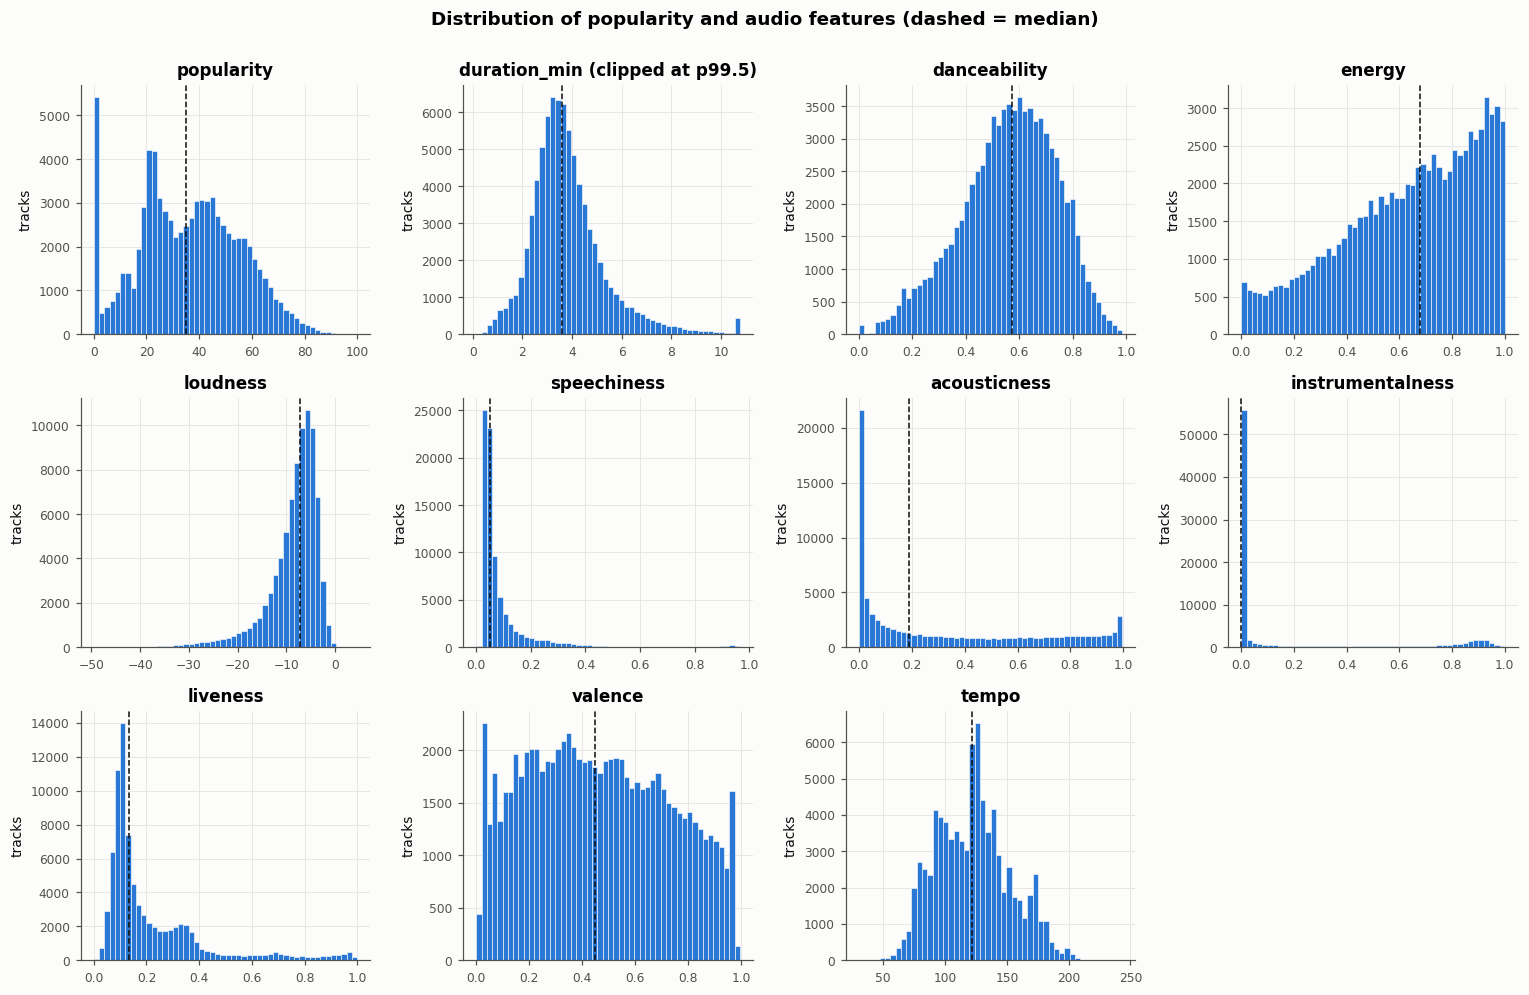

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, col in zip(axes.flat, CONT):
    data = tracks[col].dropna()
    if col == "duration_min":
        data = data.clip(upper=data.quantile(0.995))  # display only: tail of 60+ min tracks squashes the plot
    ax.hist(data, bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
    ax.axvline(data.median(), color=INK, lw=1, ls="--")
    ax.set_title(col + (" (clipped at p99.5)" if col == "duration_min" else ""))
    ax.set_ylabel("tracks")
axes.flat[-1].axis("off")
fig.suptitle("Distribution of popularity and audio features (dashed = median)", fontweight="bold", y=1.0)
fig.tight_layout()
save_fig("01_univariate_histograms")
plt.show()

In [10]:
skew_tbl = pd.DataFrame({
    "mean": tracks[CONT].mean(),
    "median": tracks[CONT].median(),
    "std": tracks[CONT].std(),
    "skewness": tracks[CONT].skew(),
    "excess_kurtosis": tracks[CONT].kurt(),
})
skew_tbl["shape"] = pd.cut(skew_tbl["skewness"], [-np.inf, -1, -0.5, 0.5, 1, np.inf],
                           labels=["strong left", "moderate left", "~symmetric", "moderate right", "strong right"])
display(skew_tbl.sort_values("skewness", key=abs, ascending=False).round(3))

,mean,median,std,skewness,excess_kurtosis,shape
duration_min,3.857,3.587,1.941,11.058,322.707,strong right
speechiness,0.089,0.049,0.117,4.485,25.503,strong right
liveness,0.220,0.133,0.198,2.031,3.861,strong right
loudness,-8.598,-7.267,5.306,-1.936,5.281,strong left
instrumentalness,0.185,0.000,0.332,1.464,0.366,strong right
acousticness,0.330,0.190,0.340,0.647,-1.080,moderate right
energy,0.635,0.678,0.259,-0.561,-0.620,moderate left
danceability,0.559,0.573,0.178,-0.390,-0.215,~symmetric
tempo,122.352,122.045,29.703,0.278,-0.410,~symmetric
valence,0.463,0.449,0.263,0.151,-1.045,~symmetric


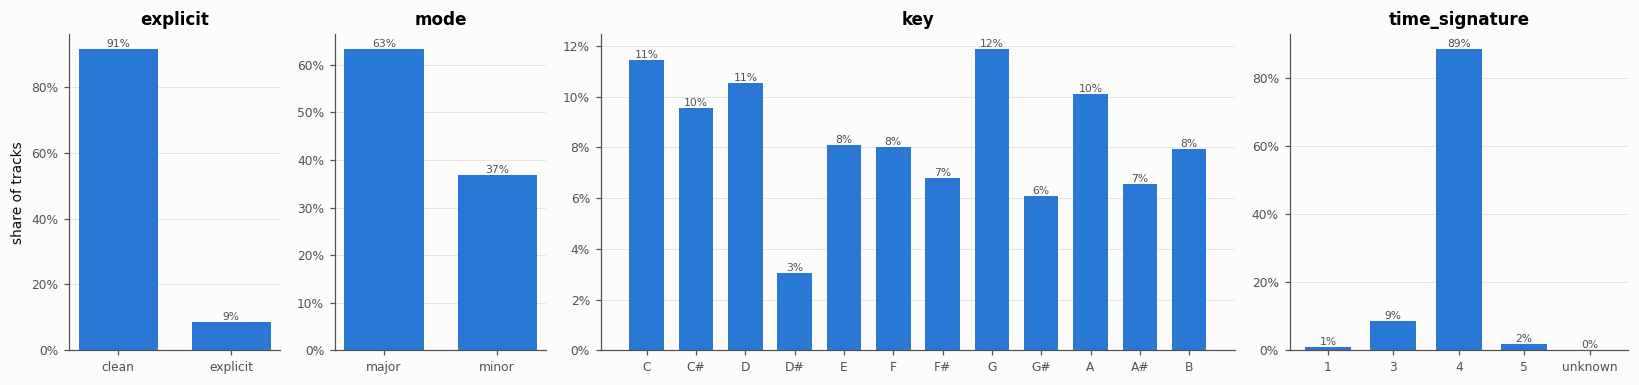

In [11]:
KEY_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
cat_specs = {
    "explicit": tracks["explicit"].map({False: "clean", True: "explicit"}),
    "mode": tracks["mode"].map({0: "minor", 1: "major"}),
    "key": pd.Series(pd.Categorical(tracks["key"].map(dict(enumerate(KEY_NAMES))), categories=KEY_NAMES)),
    "time_signature": tracks["time_signature"].astype("string").fillna("unknown"),
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 3, 1.6]})
for ax, (name, s) in zip(axes, cat_specs.items()):
    counts = s.value_counts(sort=False) if name == "key" else s.value_counts().sort_index()
    share = counts / counts.sum()
    bars = ax.bar(counts.index.astype(str), share.values, color=BLUE, width=0.7)
    for b, v in zip(bars, share.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.0%}", ha="center", va="bottom", fontsize=7, color=MUTED)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_title(name)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("share of tracks")
fig.tight_layout()
save_fig("02_categorical_bar_charts")
plt.show()

**E1 findings**
* **Popularity** is roughly symmetric (skew 0.08), but there is a spike at **0**: 4,758 songs (5.8%). They cluster in a few genres (iranian, romance, latin, ...; see E4). These look like delisted or regional tracks rather than measurements of "unpopular". **For modelling, try both with and without them, or add a `popularity == 0` flag.**
* **Strongly skewed:** `duration_min` (skew 11, a tail of 60-90 min DJ mixes), `speechiness` (4.5), `liveness` (2.0), `loudness` (-1.9, left tail of quiet classical/ambient), and `instrumentalness` (1.5, bimodal: most tracks are ~0 and a cluster sits at 0.8-1). Use log or rank transforms, or binarise (e.g. `instrumentalness > 0.5`), before any linear model.
* `acousticness` is U-shaped and `energy` is left-skewed. `danceability`, `valence`, `tempo` are close to symmetric.
* **Categorical:** only 9% of songs are explicit, 63% are in major mode, and the most common keys are G, C and D (D# is rare at 3%). 89% are in 4/4 time.

## E2. Correlation analysis

Both **Pearson** (linear) and **Spearman** (rank, monotonic) correlations are computed on `tracks`.
Several features are heavily skewed (see the E1 skewness table), so a large gap between the two values means the relationship is non-linear or driven by outliers.
Binary and categorical variables (`explicit`, `mode`, `key`, `time_signature`) are compared with boxplots in E3 instead.

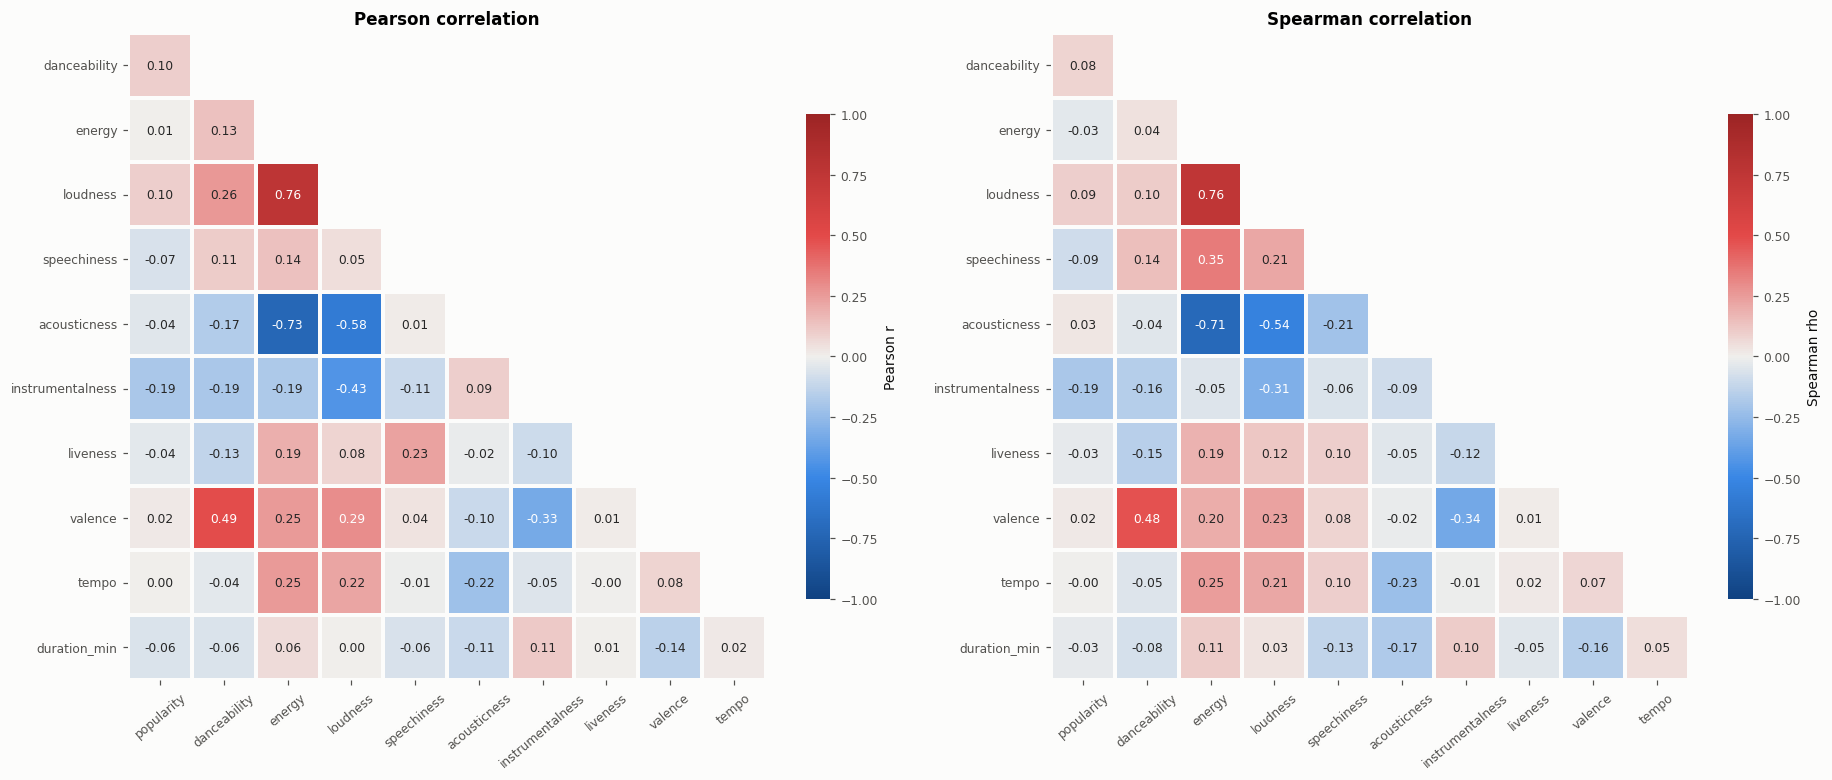

In [12]:
CORR = ["popularity", "danceability", "energy", "loudness", "speechiness", "acousticness",
        "instrumentalness", "liveness", "valence", "tempo", "duration_min"]
pearson = tracks[CORR].corr(method="pearson")
spearman = tracks[CORR].corr(method="spearman")
mask = np.triu(np.ones_like(pearson, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(17, 7.2))
for ax, (name, m) in zip(axes, [("Pearson r", pearson), ("Spearman rho", spearman)]):
    sns.heatmap(m.iloc[1:, :-1], mask=mask[1:, :-1], cmap=DIVERGING, vmin=-1, vmax=1, center=0,
                annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1.5, linecolor="#fcfcfb",
                cbar_kws={"label": name, "shrink": 0.75}, ax=ax)
    ax.set_title(f"{name.split()[0]} correlation"); ax.grid(False)
    ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
save_fig("03_correlation_heatmaps_pearson_spearman")
plt.show()

In [13]:
def lower_pairs(m, name):
    return (m.where(~mask).stack().rename(name).rename_axis(["feature_1", "feature_2"]))

pair_tbl = pd.concat([lower_pairs(pearson, "pearson"), lower_pairs(spearman, "spearman")], axis=1).reset_index()
pair_tbl["max_abs"] = pair_tbl[["pearson", "spearman"]].abs().max(axis=1)
pair_tbl["gap_s_minus_p"] = pair_tbl["spearman"] - pair_tbl["pearson"]
strong = pair_tbl[pair_tbl["max_abs"] > 0.5].sort_values("max_abs", ascending=False).reset_index(drop=True)
print("Feature pairs with |Pearson| or |Spearman| > 0.5, sorted by the larger absolute value:")
display(strong.round(3))

Feature pairs with |Pearson| or |Spearman| > 0.5, sorted by the larger absolute value:


,feature_1,feature_2,pearson,spearman,max_abs,gap_s_minus_p
0,loudness,energy,0.761,0.756,0.761,-0.005
1,acousticness,energy,-0.731,-0.713,0.731,0.018
2,acousticness,loudness,-0.582,-0.538,0.582,0.044


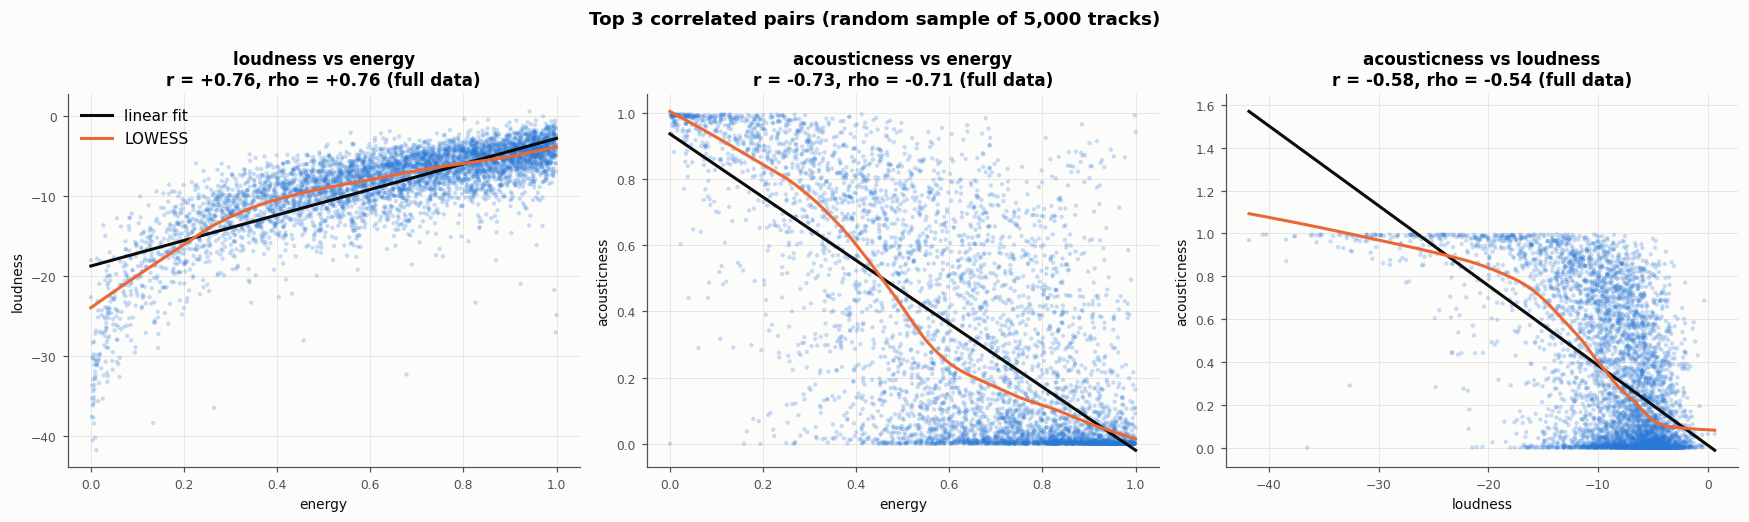

In [14]:
# Scatter plots for the 3 strongest pairs, on a 5,000-row random sample
sample = tracks[CORR].dropna().sample(5_000, random_state=42)
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (_, row) in zip(axes, strong.head(3).iterrows()):
    x, y = sample[row.feature_2], sample[row.feature_1]
    ax.scatter(x, y, s=8, alpha=0.25, color=BLUE, edgecolor="none")
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, intercept + slope * xs, color=INK, lw=2, label="linear fit")
    lw = lowess(y, x, frac=0.3)
    ax.plot(lw[:, 0], lw[:, 1], color=ORANGE, lw=2, label="LOWESS")
    ax.set_xlabel(row.feature_2); ax.set_ylabel(row.feature_1)
    ax.set_title(f"{row.feature_1} vs {row.feature_2}\nr = {row.pearson:+.2f}, rho = {row.spearman:+.2f} (full data)")
axes[0].legend(loc="best")
fig.suptitle("Top 3 correlated pairs (random sample of 5,000 tracks)", fontweight="bold")
fig.tight_layout()
save_fig("04_top3_correlated_pairs_scatter")
plt.show()

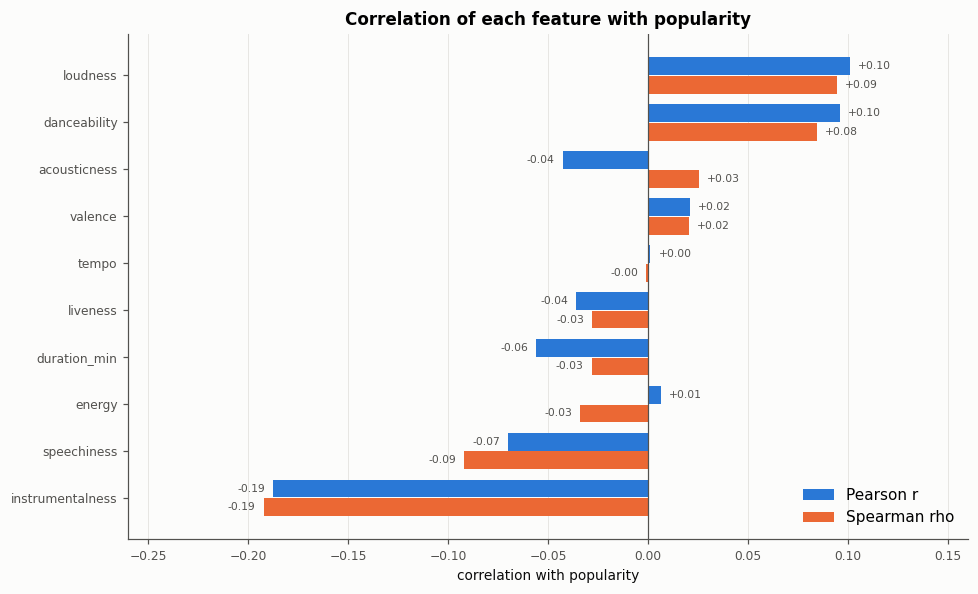

,pearson,spearman
instrumentalness,-0.188,-0.192
loudness,0.101,0.094
speechiness,-0.070,-0.092
danceability,0.096,0.084
energy,0.006,-0.034
duration_min,-0.056,-0.028
liveness,-0.036,-0.028
acousticness,-0.043,0.025
valence,0.021,0.021
tempo,0.001,-0.001


In [15]:
pop_corr = pd.DataFrame({"pearson": pearson["popularity"], "spearman": spearman["popularity"]}).drop("popularity")
pop_corr = pop_corr.sort_values("spearman")
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(pop_corr)); h = 0.38
ax.barh(y + h/2 + 0.01, pop_corr["pearson"], h, color=BLUE, label="Pearson r")
ax.barh(y - h/2 - 0.01, pop_corr["spearman"], h, color=ORANGE, label="Spearman rho")
ax.set_yticks(y); ax.set_yticklabels(pop_corr.index)
ax.axvline(0, color=MUTED, lw=0.8)
for yy, (p, s) in zip(y, pop_corr[["pearson", "spearman"]].values):
    for v, off in [(p, h/2 + 0.01), (s, -h/2 - 0.01)]:
        ax.text(v + (0.004 if v >= 0 else -0.004), yy + off, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=7, color=MUTED)
ax.set_xlim(-0.26, 0.16)
ax.set_xlabel("correlation with popularity"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Correlation of each feature with popularity")
fig.tight_layout()
save_fig("05_feature_correlation_with_popularity")
plt.show()
display(pop_corr.sort_values("spearman", key=abs, ascending=False).round(3))

In [16]:
# Variance inflation factor: how much each predictor is explained by the others (popularity is the target, so excluded)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def vif_table(cols):
    X = add_constant(tracks[cols].dropna())
    return (pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=cols, name="VIF")
              .sort_values(ascending=False))

predictors = [c for c in CORR if c != "popularity"]
vif = vif_table(predictors).to_frame()
vif["tolerance"] = 1 / vif["VIF"]
vif["flag"] = pd.cut(vif["VIF"], [0, 5, 10, np.inf], labels=["ok (<5)", "moderate (5-10)", "high (>10)"])
display(vif.round(2))

# Sensitivity check: drop the single most collinear feature and recompute
worst = vif.index[0]
print(f"VIF after dropping '{worst}':")
display(vif_table([c for c in predictors if c != worst]).round(2).to_frame())

,VIF,tolerance,flag
energy,4.31,0.23,ok (<5)
loudness,3.29,0.30,ok (<5)
acousticness,2.44,0.41,ok (<5)
valence,1.59,0.63,ok (<5)
danceability,1.51,0.66,ok (<5)
instrumentalness,1.47,0.68,ok (<5)
liveness,1.17,0.86,ok (<5)
speechiness,1.15,0.87,ok (<5)
tempo,1.09,0.92,ok (<5)
duration_min,1.05,0.95,ok (<5)


VIF after dropping 'energy':


,VIF
loudness,2.04
acousticness,1.64
valence,1.48
danceability,1.44
instrumentalness,1.38
liveness,1.11
speechiness,1.09
tempo,1.09
duration_min,1.05


**E2 findings**
* **Strong pairs (|corr| > 0.5):** only three, and Pearson and Spearman agree on all of them:
  * energy-loudness (r = +0.76)
  * energy-acousticness (-0.73)
  * loudness-acousticness (-0.58)

  Together they form one "intensity" axis: loud, energetic, non-acoustic tracks vs. quiet acoustic ones. The next strongest pair is danceability-valence (+0.49).
* **Pearson vs Spearman:** the gaps show where relationships aren't linear:
  * speechiness-energy: rho 0.35 vs r 0.14, so the relationship is monotonic but compressed by speechiness's long tail
  * instrumentalness-loudness: r -0.43 vs rho -0.31, driven by a cluster of quiet, purely instrumental tracks
  * acousticness-popularity: the sign flips (r -0.04, rho +0.03)
* **Scatter plots:** the LOWESS curves bend away from the straight lines.
  * Loudness rises steeply with energy below about 0.3, then flattens.
  * Acousticness drops sharply once energy passes about 0.4.

  A single linear coefficient understates these relationships at the extremes.
* **Correlation with popularity:** every feature is weak (|corr| <= 0.19). Ranked by strength:
  * instrumentalness (-0.19), the strongest
  * loudness (+0.10)
  * danceability (+0.10)
  * speechiness (-0.09)

  Energy, valence and tempo are about 0 in both measures. The decile plots in E3 explain why: energy, valence and duration have **inverted-U** relationships with popularity, which cancel out in a single correlation.
* **VIF:** every VIF is **below 5** (energy 4.3, loudness 3.3, acousticness 2.4; everything else below 1.6). So multicollinearity is moderate and **not a reason to drop features**. Dropping energy brings every VIF down to about 2 or below. If coefficient interpretability matters in a linear model, consider dropping energy or replacing the three intensity features with one principal component. Tree models need no change.

## E3. What drives popularity?

Step 6 of the correlation analysis (mean popularity by decile) lives here. Each feature is cut into deciles (equal-count bins). Features with many tied values, such as `instrumentalness` (most tracks are 0), end up with fewer bins. The line is mean popularity per bin and the band is a 95% CI.

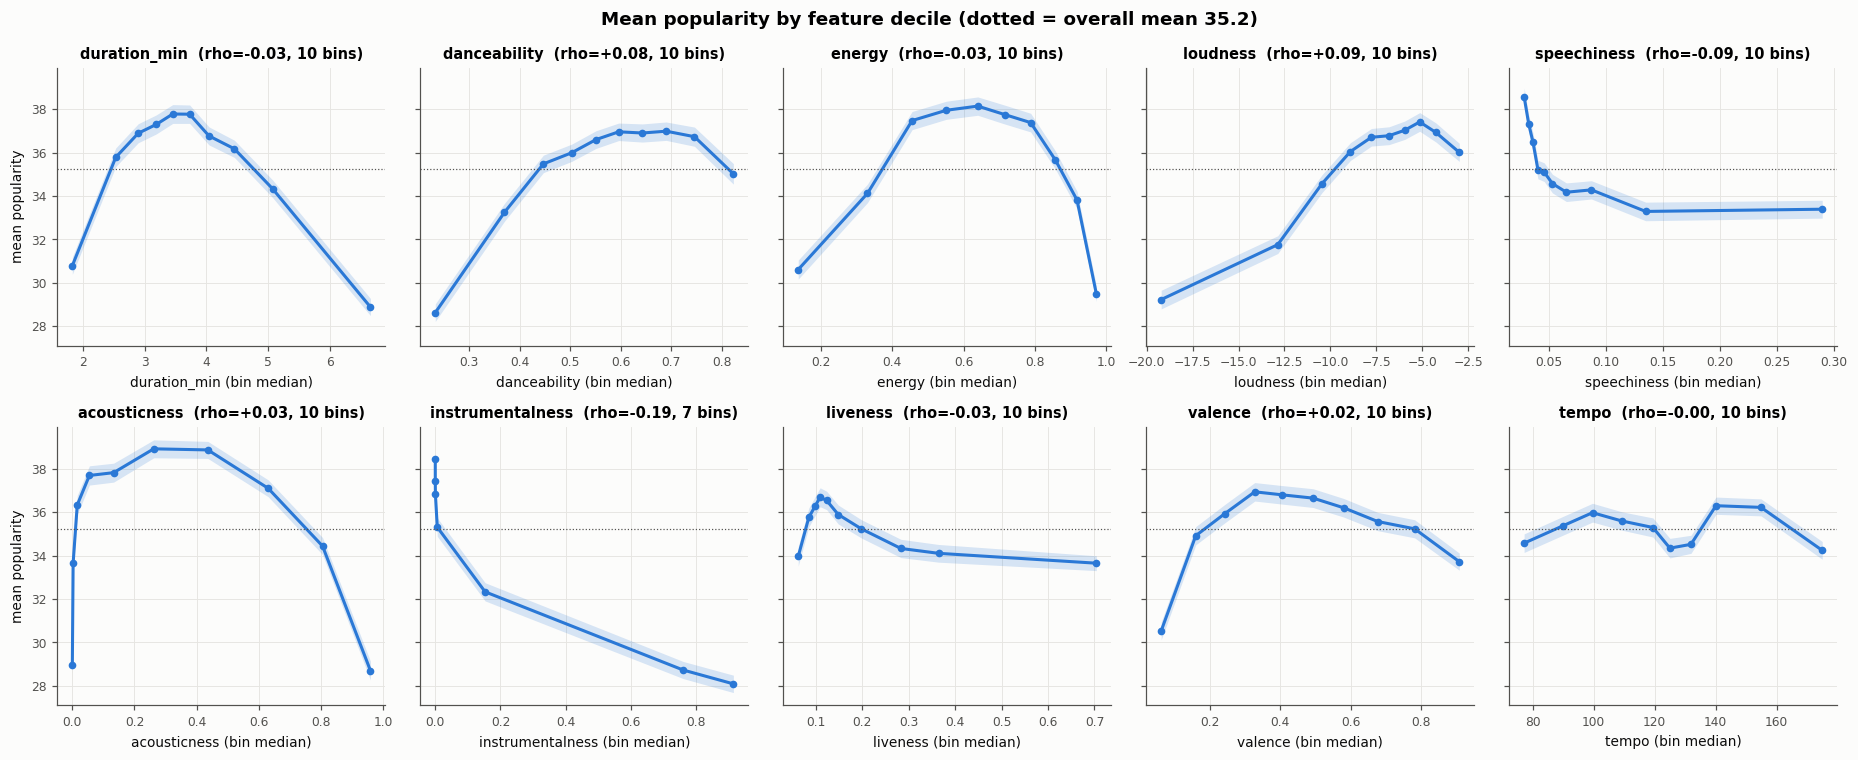

,lowest_bin_mean,highest_bin_mean,peak_bin_mean,peak_at_feature_value,min_bin_mean,range
feature,,,,,,
instrumentalness,38.43,28.09,38.43,0.00,28.09,10.34
acousticness,28.94,28.70,38.92,0.26,28.70,10.22
duration_min,30.79,28.89,37.78,3.46,28.89,8.89
energy,30.61,29.50,38.14,0.64,29.50,8.64
danceability,28.63,35.02,36.99,0.69,28.63,8.36
loudness,29.23,36.01,37.41,-5.14,29.23,8.18
valence,30.53,33.72,36.94,0.33,30.53,6.41
speechiness,38.58,33.39,38.58,0.03,33.29,5.29
liveness,33.97,33.65,36.69,0.11,33.65,3.04


In [17]:
feat_drivers = ["duration_min"] + AUDIO
fig, axes = plt.subplots(2, 5, figsize=(17, 7), sharey=True)
overall = tracks["popularity"].mean()
decile_summary = []
for ax, col in zip(axes.flat, feat_drivers):
    sub = tracks[[col, "popularity"]].dropna()
    sub["bin"] = pd.qcut(sub[col], 10, duplicates="drop")
    g = sub.groupby("bin", observed=True).agg(x=(col, "median"), mean=("popularity", "mean"),
                                              sd=("popularity", "std"), n=("popularity", "size"))
    ci = 1.96 * g["sd"] / np.sqrt(g["n"])
    decile_summary.append({"feature": col, "lowest_bin_mean": g["mean"].iloc[0], "highest_bin_mean": g["mean"].iloc[-1],
                           "peak_bin_mean": g["mean"].max(), "peak_at_feature_value": g["x"][g["mean"].idxmax()],
                           "min_bin_mean": g["mean"].min(), "range": g["mean"].max() - g["mean"].min()})
    ax.fill_between(g["x"], g["mean"] - ci, g["mean"] + ci, color=BLUE, alpha=0.18, lw=0)
    ax.plot(g["x"], g["mean"], color=BLUE, lw=2, marker="o", ms=4)
    ax.axhline(overall, color=MUTED, lw=0.8, ls=":")
    r = stats.spearmanr(sub[col], sub["popularity"]).correlation
    ax.set_title(f"{col}  (rho={r:+.2f}, {len(g)} bins)", fontsize=9.5)
    ax.set_xlabel(f"{col} (bin median)")
axes[0, 0].set_ylabel("mean popularity"); axes[1, 0].set_ylabel("mean popularity")
fig.suptitle(f"Mean popularity by feature decile (dotted = overall mean {overall:.1f})", fontweight="bold")
fig.tight_layout()
save_fig("06_popularity_by_feature_decile")
plt.show()
display(pd.DataFrame(decile_summary).set_index("feature").sort_values("range", ascending=False).round(2))

**E3 findings (deciles)**
* The decile curves show **non-linear, inverted-U** relationships that the near-zero rho values hide. Mean popularity peaks at mid-range **duration (~3-4 min)**, **energy (0.45-0.8)**, **danceability (0.6-0.75)**, **acousticness (0.2-0.45)** and **valence (0.3-0.5)**. It falls off at both extremes, by up to ~10 points (acousticness range 10.2, duration 8.9, energy 8.7).
* The relationships with **instrumentalness** (purely instrumental tracks average ~28 vs ~38) and **speechiness** go down steadily. **Loudness** rises up to about -5 dB.
* Tempo has little effect.
* Implication: tree-based models, or splines/binned features, should beat a plain linear model on these features.

/var/folders/_q/x04dmzfs4rx7j51llpf_rjsm0000gn/T/ipykernel_40600/19165485.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], widths=0.5,
/var/folders/_q/x04dmzfs4rx7j51llpf_rjsm0000gn/T/ipykernel_40600/19165485.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], widths=0.5,
/var/folders/_q/x04dmzfs4rx7j51llpf_rjsm0000gn/T/ipykernel_40600/19165485.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})"

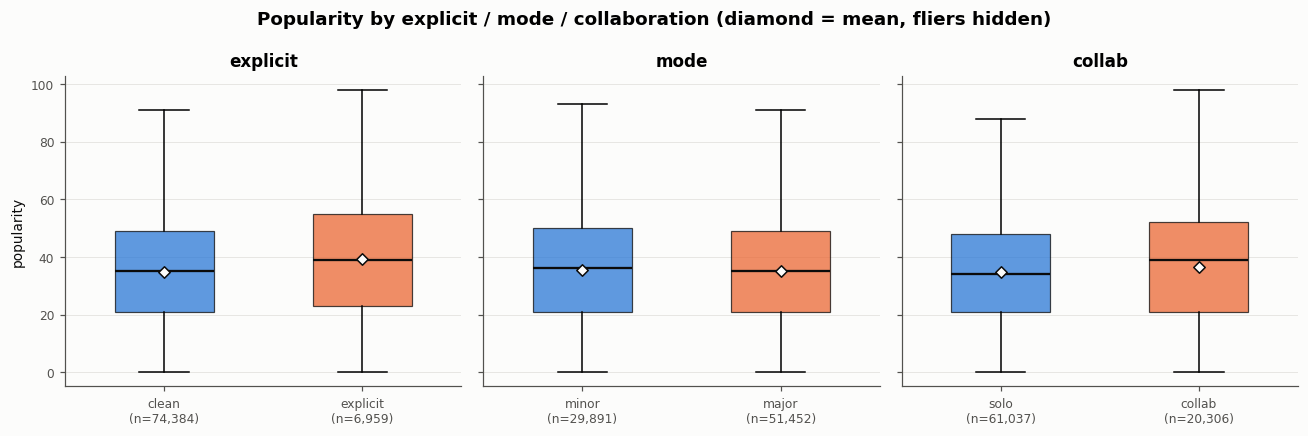

,variable,group_a,group_b,mean_a,mean_b,median_a,median_b,mean_diff_b_minus_a,mann_whitney_p,rank_biserial
0,explicit,clean,explicit,34.8588,39.4242,35.0,39.0,4.5654,0.0000,0.1217
1,mode,minor,major,35.3621,35.1838,36.0,35.0,-0.1783,0.2246,-0.0051
2,collab,solo,collab,34.7899,36.6305,34.0,39.0,1.8406,0.0000,0.0645


In [18]:
groups = {
    "explicit": tracks["explicit"].map({False: "clean", True: "explicit"}),
    "mode": tracks["mode"].map({0: "minor", 1: "major"}),
    "collab": tracks["collab"].map({False: "solo", True: "collab"}),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
rows = []
for ax, (name, lab) in zip(axes, groups.items()):
    order = {"explicit": ["clean", "explicit"], "mode": ["minor", "major"], "collab": ["solo", "collab"]}[name]
    data = [tracks.loc[lab == o, "popularity"] for o in order]
    bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], widths=0.5,
                    patch_artist=True, showfliers=False, medianprops={"color": INK, "lw": 1.5})
    for patch, c in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set(facecolor=c, alpha=0.75, edgecolor=INK, linewidth=0.8)
    for i, d in enumerate(data, 1):
        ax.scatter(i, d.mean(), marker="D", s=28, color="#fcfcfb", edgecolor=INK, zorder=3)
    ax.set_title(name); ax.grid(axis="x", visible=False)
    u = stats.mannwhitneyu(data[0], data[1])
    rows.append({"variable": name, "group_a": order[0], "group_b": order[1],
                 "mean_a": data[0].mean(), "mean_b": data[1].mean(),
                 "median_a": data[0].median(), "median_b": data[1].median(),
                 "mean_diff_b_minus_a": data[1].mean() - data[0].mean(),
                 "mann_whitney_p": u.pvalue,
                 "rank_biserial": 1 - 2 * u.statistic / (len(data[0]) * len(data[1]))})
axes[0].set_ylabel("popularity")
fig.suptitle("Popularity by explicit / mode / collaboration (diamond = mean, fliers hidden)", fontweight="bold")
fig.tight_layout()
save_fig("07_popularity_boxplots_explicit_mode_collab")
plt.show()
display(pd.DataFrame(rows).round(4))

/var/folders/_q/x04dmzfs4rx7j51llpf_rjsm0000gn/T/ipykernel_40600/2232378981.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], widths=0.55,
/var/folders/_q/x04dmzfs4rx7j51llpf_rjsm0000gn/T/ipykernel_40600/2232378981.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], widths=0.55,


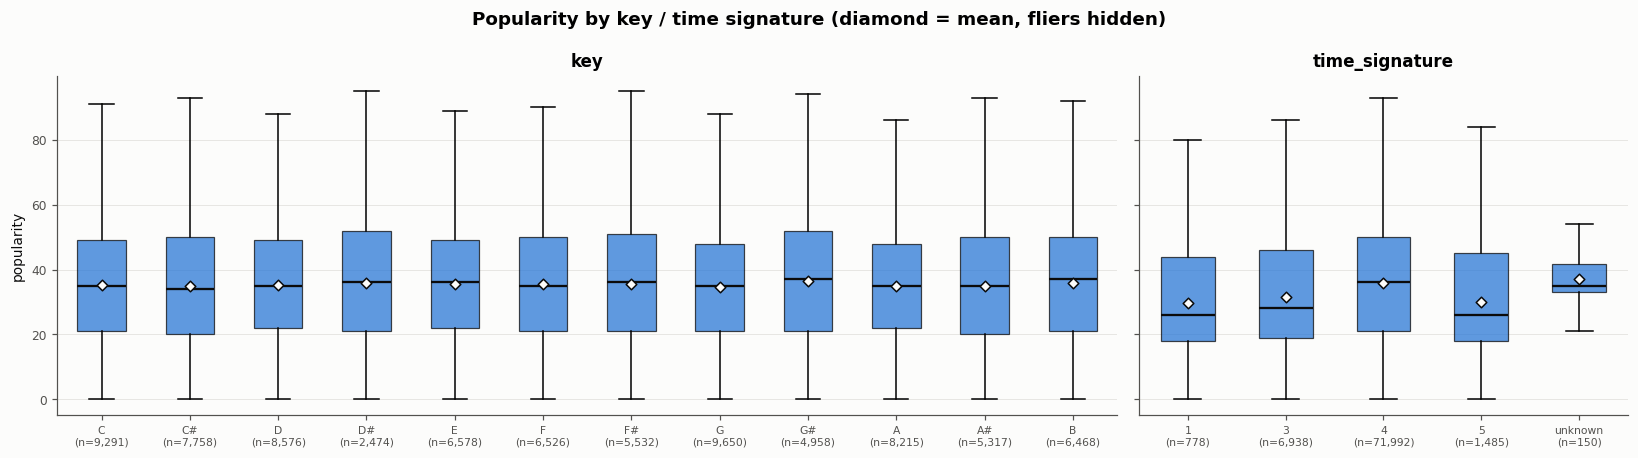

,variable,levels,kruskal_H,p_value,epsilon_squared,mean_range
0,key,12,59.1740,0.0,0.0007,34.5 - 36.4
1,time_signature,5,494.4353,0.0,0.0061,29.6 - 36.9


In [19]:
# key and time_signature have more than two levels -> Kruskal-Wallis test
KEY_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
multi = {
    "key": (tracks["key"].map(dict(enumerate(KEY_NAMES))), KEY_NAMES),
    "time_signature": (tracks["time_signature"].astype("string").fillna("unknown"), ["1", "3", "4", "5", "unknown"]),
}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.6, 1.2]}, sharey=True)
kw_rows = []
for ax, (name, (lab, order)) in zip(axes, multi.items()):
    order = [o for o in order if (lab == o).any()]
    data = [tracks.loc[lab == o, "popularity"] for o in order]
    bp = ax.boxplot(data, labels=[f"{o}\n(n={len(d):,})" for o, d in zip(order, data)], widths=0.55,
                    patch_artist=True, showfliers=False, medianprops={"color": INK, "lw": 1.5})
    for patch in bp["boxes"]:
        patch.set(facecolor=BLUE, alpha=0.75, edgecolor=INK, linewidth=0.8)
    for i, d in enumerate(data, 1):
        ax.scatter(i, d.mean(), marker="D", s=24, color="#fcfcfb", edgecolor=INK, zorder=3)
    ax.tick_params(axis="x", labelsize=7)
    ax.set_title(name); ax.grid(axis="x", visible=False)
    h = stats.kruskal(*data)
    n = sum(len(d) for d in data)
    kw_rows.append({"variable": name, "levels": len(data), "kruskal_H": h.statistic, "p_value": h.pvalue,
                    "epsilon_squared": h.statistic / (n - 1),
                    "mean_range": f"{min(d.mean() for d in data):.1f} - {max(d.mean() for d in data):.1f}"})
axes[0].set_ylabel("popularity")
fig.suptitle("Popularity by key / time signature (diamond = mean, fliers hidden)", fontweight="bold")
fig.tight_layout()
save_fig("08_popularity_boxplots_key_time_signature")
plt.show()
display(pd.DataFrame(kw_rows).round(4))

**E3 findings (groups)**
* **Explicit** tracks are more popular: mean 39.4 vs 34.9 (+4.6, Mann-Whitney p < 0.001, rank-biserial 0.12, a small effect).
* **Collaborations** are more popular than solo tracks: median 39 vs 34 (+1.8 mean, p < 0.001, small effect).
* **Mode** (major vs minor) makes no difference (p = 0.22).
* **Key:** the differences are statistically significant only because the sample is large (Kruskal-Wallis p < 0.001). The effect is negligible: epsilon-squared is 0.0007, and key means range only from 34.5 to 36.4.
* **Time signature:** 4/4 tracks are more popular (median 36) than 1, 3 and 5 (medians 26-28). The effect is small (epsilon-squared 0.006), and part of it is likely genre mix: non-4/4 tracks are over-represented in sleep, comedy, ambient, opera/classical and romance. Each of these makes up 3-6% of the non-4/4 tracks, vs. about 0.9% if spread evenly, and several of them are the low-popularity genres from E4.
* Every effect here is small compared with the spread inside each group, so none of these variables separates popular from unpopular tracks on its own.

## E4. Genre analysis (uses `genre_df`)

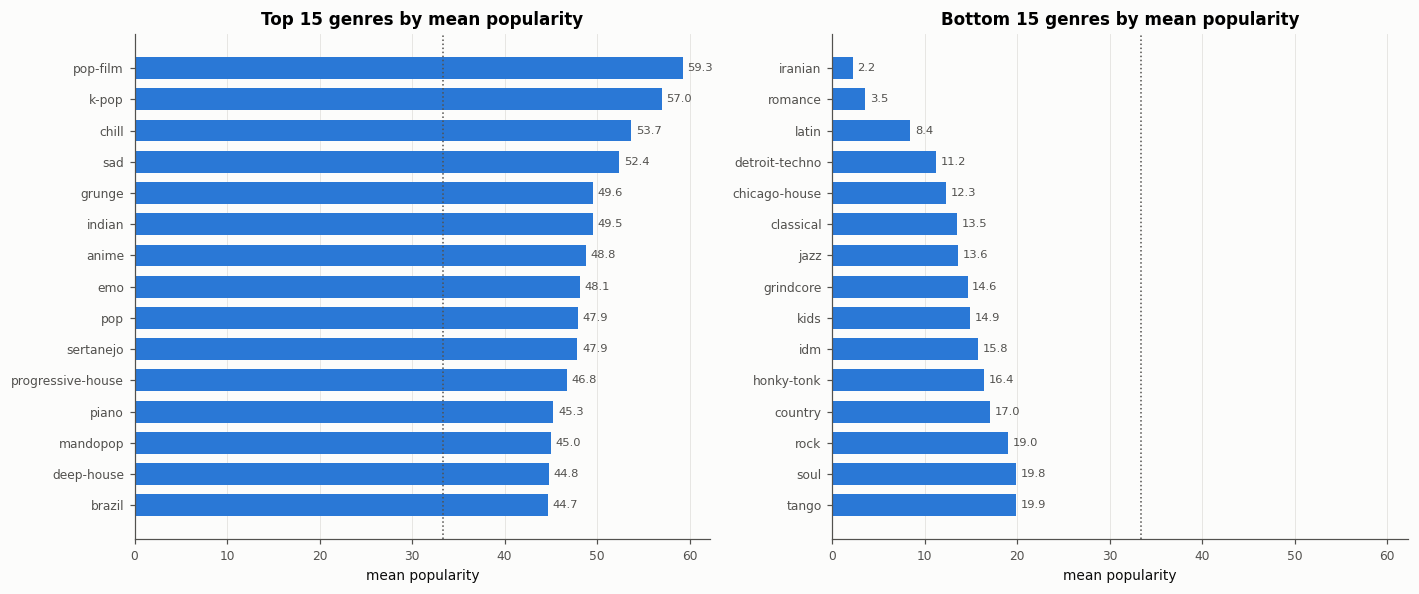

In [20]:
genre_pop = genre_df.groupby("track_genre")["popularity"].agg(["mean", "median", "std", "size"]).sort_values("mean")
top15, bottom15 = genre_pop.tail(15), genre_pop.head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True)
for ax, tbl, title in [(axes[0], top15, "Top 15 genres"), (axes[1], bottom15.iloc[::-1], "Bottom 15 genres")]:
    ax.barh(tbl.index, tbl["mean"], color=BLUE, height=0.7)
    for y, v in enumerate(tbl["mean"]):
        ax.text(v + 0.5, y, f"{v:.1f}", va="center", fontsize=7.5, color=MUTED)
    ax.axvline(genre_df["popularity"].mean(), color=MUTED, ls=":", lw=1)
    ax.set_title(title + " by mean popularity"); ax.set_xlabel("mean popularity"); ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig("09_genre_top_bottom_popularity")
plt.show()

**E4 findings (popularity)**
* Genre is the strongest single factor seen so far. Genre means range from **2.2 (iranian) to 59.3 (pop-film)**.
* The top genres are pop-film, k-pop, chill, sad, grunge and indian.
* At the bottom are iranian (2.2), romance (3.5), latin (8.4), and also jazz, classical and country. These low means come mostly from the popularity-0 tracks in E1. **About 60-68% of the rows in jazz, iranian, romance, soul, latin and country have popularity = 0.** Latin is especially odd: the top-15 track list in E5 is full of latin/reggaeton hits, yet `latin` averages 8.4 (latino 25.8, reggaeton 23.9). These zeros **likely reflect how the data was collected, not real listener taste**. Mention this in the report, and when modelling popularity, flag the zeros or model them separately.

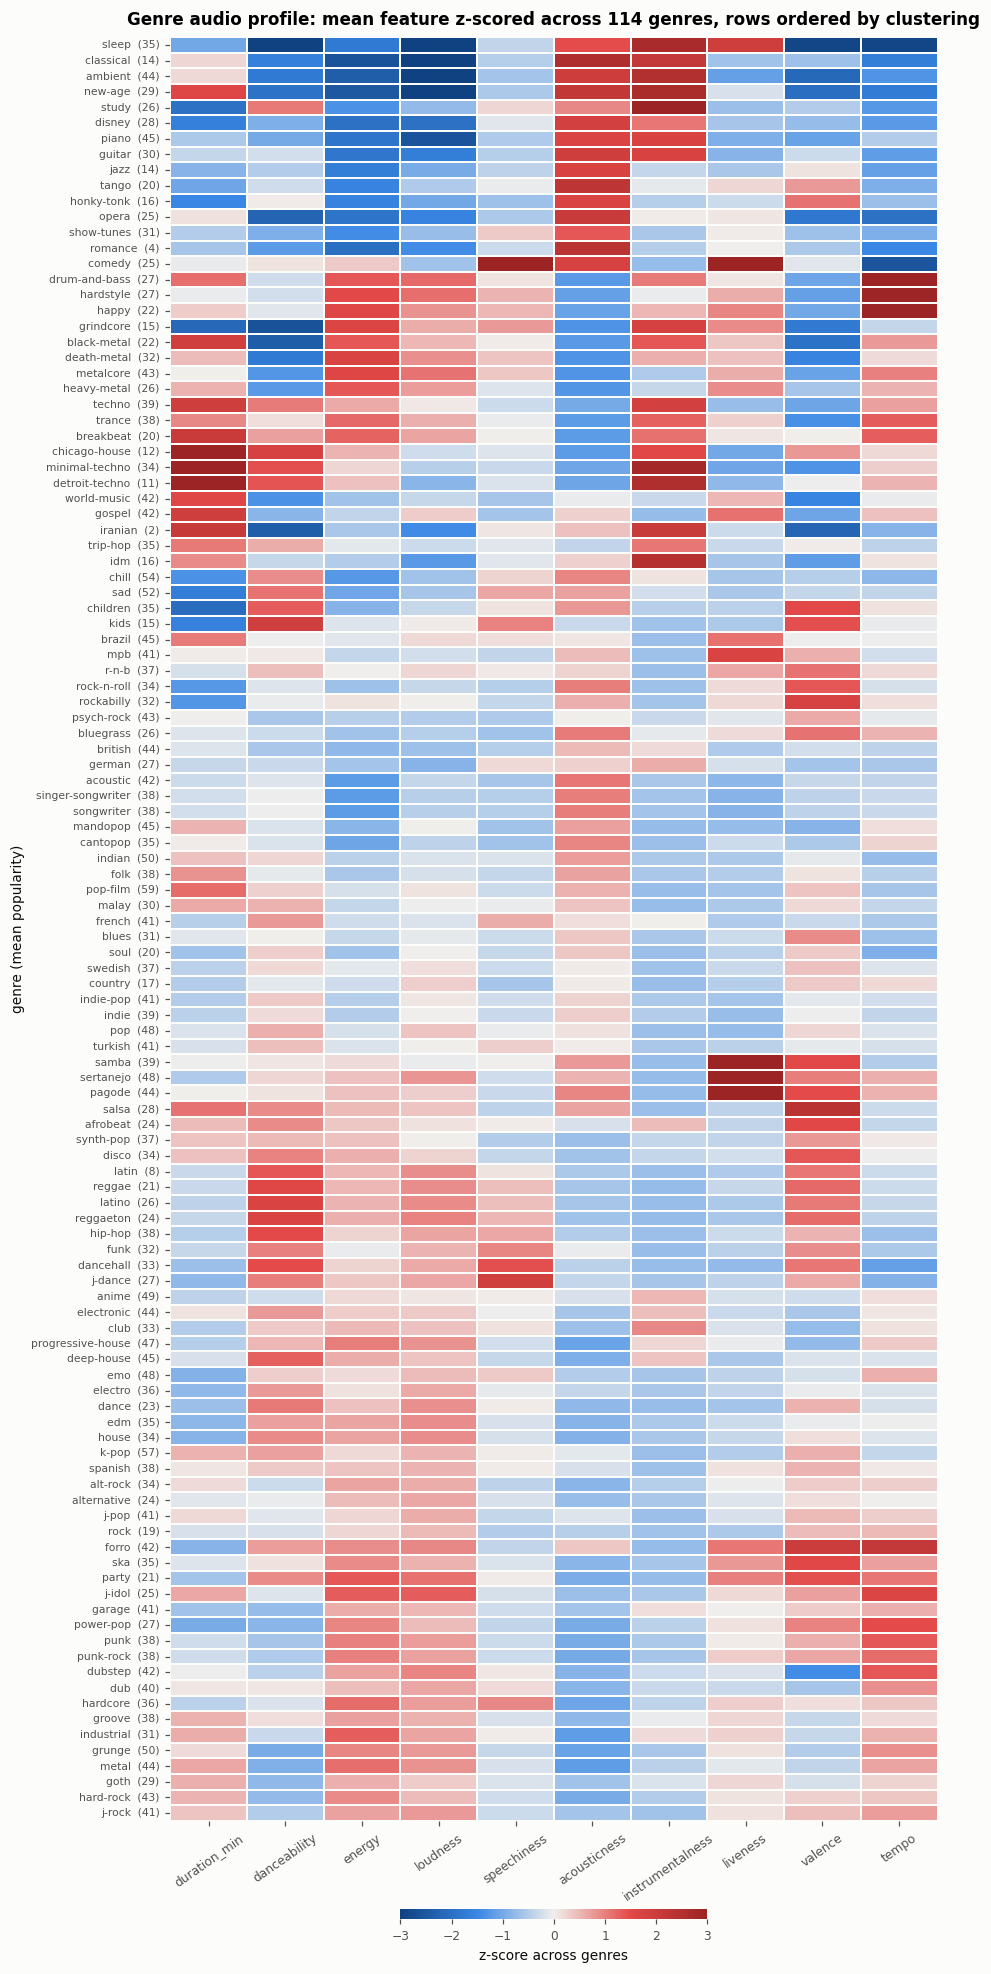

Most extreme genre profiles (|z| > 2.5):


,track_genre,feature,z
0,comedy,speechiness,9.51
1,comedy,liveness,6.02
2,sleep,loudness,-4.71
3,pagode,liveness,4.11
4,drum-and-bass,tempo,3.95
5,happy,tempo,3.67
6,sleep,danceability,-3.55
7,sertanejo,liveness,3.50
8,classical,loudness,-3.46
9,detroit-techno,duration_min,3.30


In [21]:
genre_feat = genre_df.groupby("track_genre")[["popularity", "duration_min"] + AUDIO].mean()
genre_z = (genre_feat - genre_feat.mean()) / genre_feat.std()
genre_z = genre_z.loc[genre_pop.index[::-1]]  # most popular genre on top
from scipy.cluster.hierarchy import linkage, leaves_list
prof = genre_z.drop(columns="popularity")
prof = prof.iloc[leaves_list(linkage(prof.values, "ward"))]  # similar genres sit next to each other
prof.index = [f"{g}  ({genre_feat.loc[g, 'popularity']:.0f})" for g in prof.index]
fig, ax = plt.subplots(figsize=(9, 26))
sns.heatmap(prof, cmap=DIVERGING, center=0, vmin=-3, vmax=3, linewidths=0.3, linecolor="#fcfcfb",
            yticklabels=True, cbar_kws={"label": "z-score across genres", "shrink": 0.4, "location": "bottom", "pad": 0.04, "aspect": 30}, ax=ax)
ax.tick_params(axis="y", labelsize=7); ax.tick_params(axis="x", labelsize=8, rotation=35)
ax.set_ylabel("genre (mean popularity)"); ax.grid(False)
ax.set_title("Genre audio profile: mean feature z-scored across 114 genres, rows ordered by clustering", pad=8)
save_fig("10_genre_audio_profile_heatmap")
plt.show()

print("Most extreme genre profiles (|z| > 2.5):")
ext = genre_z.drop(columns="popularity").stack().rename("z").reset_index()
display(ext[ext["z"].abs() > 2.5].sort_values("z", key=abs, ascending=False)
          .rename(columns={"level_1": "feature"}).reset_index(drop=True).round(2))

**E4 findings (audio profile)**
* The clustering finds clear genre families: a **quiet/acoustic** block (classical, ambient, new-age, piano, sleep, study, opera, disney), a **loud/high-energy** block (metal, hardcore, punk, grunge), a **long, instrumental electronic** block (minimal-, detroit-techno, chicago-house, trance), and a **danceable, high-valence** block (latin, reggaeton, reggae, hip-hop, funk, dancehall).
* The single most extreme profile is **comedy speechiness (z = 9.5)**. Comedy is mostly spoken word, which explains most of the speechiness outliers in E6. **sleep** is extreme on almost every feature (quiet, not danceable, low tempo).

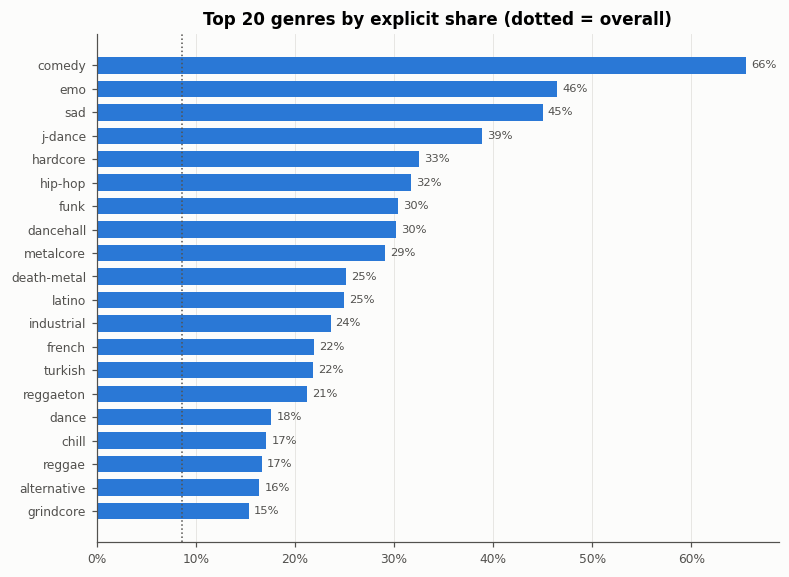

Genres with < 1% explicit tracks: 31 of 114
Explicit share vs genre mean popularity, Spearman rho: 0.077


In [22]:
explicit_share = genre_df.groupby("track_genre")["explicit"].mean().sort_values(ascending=False)
top_exp = explicit_share.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_exp.index, top_exp.values, color=BLUE, height=0.7)
for y, v in enumerate(top_exp.values):
    ax.text(v + 0.005, y, f"{v:.0%}", va="center", fontsize=7.5, color=MUTED)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.axvline(genre_df["explicit"].mean(), color=MUTED, ls=":", lw=1)
ax.set_title("Top 20 genres by explicit share (dotted = overall)"); ax.grid(axis="y", visible=False)
save_fig("11_genre_explicit_share")
plt.show()
print(f"Genres with < 1% explicit tracks: {(explicit_share < 0.01).sum()} of {len(explicit_share)}")
print("Explicit share vs genre mean popularity, Spearman rho:",
      round(stats.spearmanr(explicit_share, genre_pop.loc[explicit_share.index, "mean"]).correlation, 3))

**E4 findings (explicit)**
* Explicit content is concentrated in a few genres: **comedy (66%)**, emo (46%), sad (45%), j-dance (39%), hardcore (33%) and hip-hop (32%) lead. The overall share is about 9%.
* 31 of 114 genres have almost no explicit tracks (< 1%).
* At genre level, the explicit share barely tracks popularity (rho = 0.08). So the track-level "explicit is more popular" result in E3 is partly a **genre-mix effect**. Control for genre before reading it as causal.

13,129 of 81,343 songs (16.1%) carry more than one genre label; max = 9


,genre_a,genre_b,shared_tracks,jaccard
0,singer-songwriter,songwriter,774,0.774
1,dub,dubstep,678,0.533
2,punk,punk-rock,545,0.398
3,indie,indie-pop,452,0.319
4,latino,reggaeton,418,0.333
5,reggae,reggaeton,404,0.338
6,alt-rock,alternative,378,0.269
7,edm,house,372,0.272
8,minimal-techno,techno,315,0.188
9,brazil,gospel,311,0.185


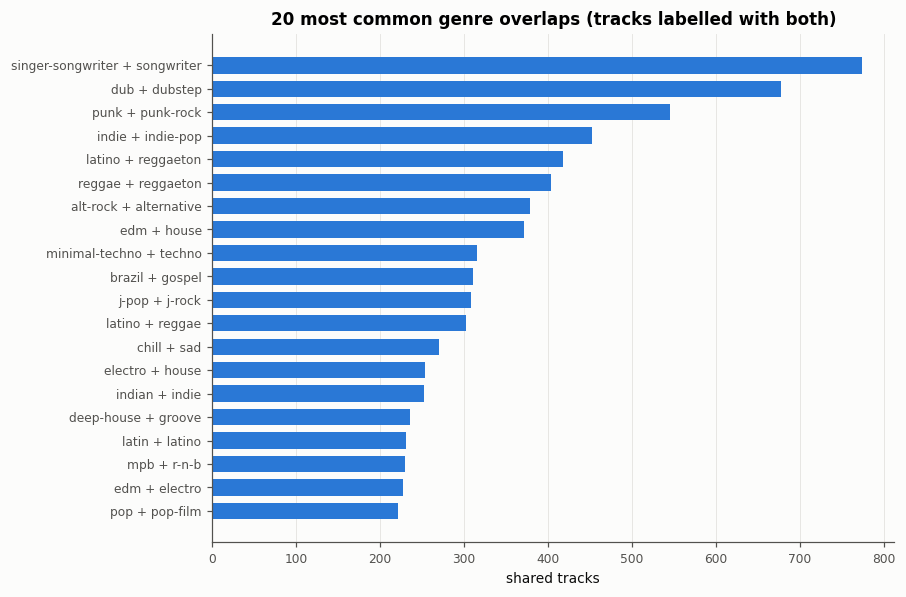

In [23]:
multi = tracks.loc[tracks["n_genres"] > 1, "genres"]
pair_counts = Counter(p for g in multi for p in combinations(g, 2))
overlap = pd.DataFrame([(a, b, n) for (a, b), n in pair_counts.most_common(20)], columns=["genre_a", "genre_b", "shared_tracks"])
# Jaccard: shared / union of the two genres' track sets
gsets = genre_df.groupby("track_genre")["track_id"].agg(set)
overlap["jaccard"] = [n / len(gsets[a] | gsets[b]) for a, b, n in overlap[["genre_a", "genre_b", "shared_tracks"]].values]
print(f"{len(multi):,} of {len(tracks):,} songs ({len(multi)/len(tracks):.1%}) carry more than one genre label; max = {tracks.n_genres.max()}")
display(overlap.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
lbl = overlap["genre_a"] + " + " + overlap["genre_b"]
ax.barh(lbl[::-1], overlap["shared_tracks"][::-1], color=BLUE, height=0.7)
ax.set_title("20 most common genre overlaps (tracks labelled with both)"); ax.set_xlabel("shared tracks")
ax.grid(axis="y", visible=False)
save_fig("12_genre_overlaps")
plt.show()

**E4 findings (overlap)**
* 16% of songs carry 2 to 9 genre labels.
* Some genre pairs are near-synonyms: **singer-songwriter / songwriter** share 77% of their tracks (Jaccard 0.77), dub / dubstep 53%, punk / punk-rock 40%.
* Spotify's genre labels therefore overlap and aren't mutually exclusive. Treat `track_genre` as a multi-label feature (multi-hot encoding), or merge the near-synonym pairs, rather than as a single class.

## E5. Artist analysis

Credits are split on `;`, so a collaboration counts toward each credited artist.

Unique credited artists: 29,858; median tracks per artist: 1; artists with >= 10 tracks: 2,390


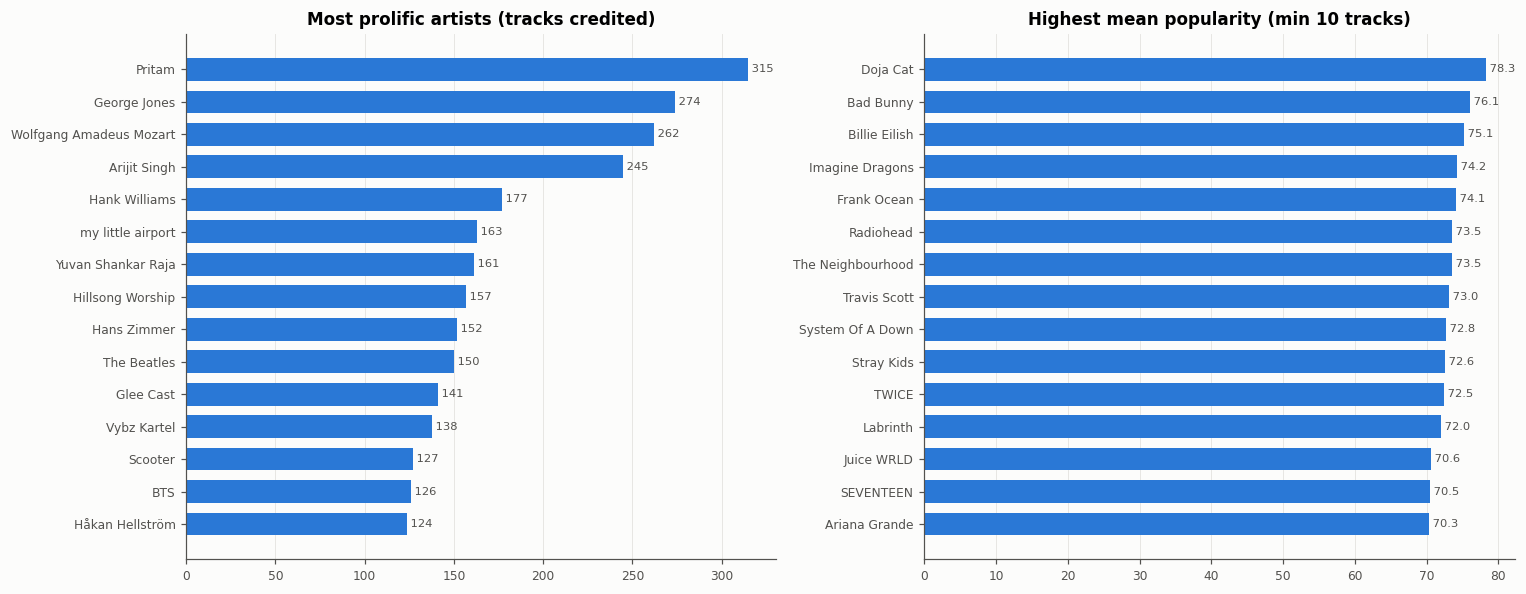

,n_tracks,mean_popularity,max_popularity
artist,,,
Pritam,315,53.7,88
George Jones,274,16.0,56
Wolfgang Amadeus Mozart,262,10.9,64
Arijit Singh,245,58.6,88
Hank Williams,177,17.3,55
my little airport,163,33.4,50
Yuvan Shankar Raja,161,51.5,74
Hillsong Worship,157,44.5,66
Hans Zimmer,152,34.4,74


,n_tracks,mean_popularity,max_popularity
artist,,,
Doja Cat,12,78.3,90
Bad Bunny,65,76.1,97
Billie Eilish,30,75.1,89
Imagine Dragons,19,74.2,89
Frank Ocean,21,74.1,85
Radiohead,11,73.5,85
The Neighbourhood,27,73.5,93
Travis Scott,22,73.0,84
System Of A Down,12,72.8,83


In [24]:
artist_long = tracks.assign(artist=tracks["artists"].str.split(";")).explode("artist")
artist_long["artist"] = artist_long["artist"].str.strip()
artist_stats = artist_long.groupby("artist")["popularity"].agg(n_tracks="size", mean_popularity="mean", max_popularity="max")
print(f"Unique credited artists: {len(artist_stats):,}; median tracks per artist: {artist_stats.n_tracks.median():.0f}; "
      f"artists with >= 10 tracks: {(artist_stats.n_tracks >= 10).sum():,}")

prolific = artist_stats.sort_values("n_tracks", ascending=False).head(15)
popular = artist_stats[artist_stats["n_tracks"] >= 10].sort_values("mean_popularity", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, tbl, col, title in [(axes[0], prolific, "n_tracks", "Most prolific artists (tracks credited)"),
                            (axes[1], popular, "mean_popularity", "Highest mean popularity (min 10 tracks)")]:
    t = tbl.iloc[::-1]
    ax.barh(t.index, t[col], color=BLUE, height=0.7)
    for y, v in enumerate(t[col]):
        ax.text(v, y, f" {v:.0f}" if col == "n_tracks" else f" {v:.1f}", va="center", fontsize=7.5, color=MUTED)
    ax.set_title(title); ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig("13_artists_prolific_and_popular")
plt.show()
display(prolific.round(1)); display(popular.round(1))

**E5 findings (artists)**
* Most artists appear only once (median 1 track); only 2,390 have 10 or more.
* The most prolific artists are mostly **catalogue-heavy** acts: Pritam, George Jones, Mozart, Hank Williams. Several of them have *low* mean popularity (Mozart 10.9, George Jones 16.0), so having many tracks doesn't mean being popular.
* The highest-mean artists (min 10 tracks) are current mainstream acts: Doja Cat (78), Bad Bunny (76, with 65 tracks), Billie Eilish, Imagine Dragons, plus K-pop groups (Stray Kids, TWICE, SEVENTEEN).
* An artist-level feature such as **mean popularity of the artist's other tracks** would likely predict popularity well. Compute it out-of-fold to avoid target leakage.

In [25]:
top_tracks = (tracks.sort_values(["popularity", "track_name"], ascending=[False, True]).head(15)
                    [["track_name", "artists", "popularity", "genres", "explicit", "duration_min", "danceability", "energy", "valence"]]
                    .reset_index(drop=True))
top_tracks.index += 1
display(top_tracks.round(2))

,track_name,artists,popularity,genres,explicit,duration_min,danceability,energy,valence
1,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100,"[dance, pop]",False,2.62,0.71,0.47,0.24
2,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99,[hip-hop],False,3.32,0.62,0.78,0.55
3,I'm Good (Blue),David Guetta;Bebe Rexha,98,"[dance, edm, pop]",True,2.92,0.56,0.96,0.30
4,La Bachata,Manuel Turizo,98,"[latin, latino, reggae, reggaeton]",False,2.71,0.84,0.68,0.85
5,Me Porto Bonito,Bad Bunny;Chencho Corleone,97,"[latin, latino, reggae, reggaeton]",True,2.98,0.91,0.71,0.42
6,Tití Me Preguntó,Bad Bunny,97,"[latin, latino, reggae, reggaeton]",False,4.06,0.65,0.72,0.19
7,Efecto,Bad Bunny,96,"[latin, latino, reggae, reggaeton]",False,3.55,0.80,0.48,0.23
8,I Ain't Worried,OneRepublic,96,"[piano, pop, rock]",False,2.47,0.70,0.80,0.82
9,Under The Influence,Chris Brown,96,"[dance, pop]",True,3.08,0.73,0.69,0.31
10,As It Was,Harry Styles,95,[pop],False,2.79,0.52,0.73,0.66


**E5 findings (top tracks)**
* The top 15 are all 2022 hits (Unholy, Quevedo BZRP 52, I'm Good, As It Was, ...), so the snapshot was taken around late 2022.
* Bad Bunny has 6 of the 15.
* They are typically short (2.5-4.3 min) and high in danceability and energy, which matches the sweet spots found in E3.

## E6. Outliers (IQR rule, checked by genre before removing anything)

A value is flagged if it is below Q1 - 1.5 IQR or above Q3 + 1.5 IQR. We compute this two ways:
* **global**: fences computed on all tracks
* **within genre**: fences computed separately inside each genre, using `genre_df`

If a value is an outlier globally but normal inside its own genre, it is a real genre trait and not an error.

,global_outlier_pct,global_outlier_pct_genre_df,within_genre_outlier_pct,pct_of_global_outliers_still_outliers_in_own_genre,share_of_outliers_in_top5_genres,top_genres
feature,,,,,,
instrumentalness,21.3,22.1,15.7,26.8,17.9,"study (968), minimal-techno (941), sleep (866)..."
speechiness,11.9,11.6,9.4,55.2,20.5,"comedy (885), j-dance (612), dancehall (495), ..."
liveness,8.0,7.6,7.3,57.3,26.5,"comedy (739), pagode (463), sertanejo (402), s..."
loudness,5.7,5.4,2.5,15.2,48.3,"sleep (770), classical (602), new-age (582), a..."
duration_min,4.6,4.9,3.7,42.1,30.0,"minimal-techno (410), detroit-techno (395), ch..."
danceability,0.5,0.5,0.8,3.6,74.1,"sleep (267), iranian (82), black-metal (38), g..."
tempo,0.4,0.4,2.4,48.7,21.4,"piano (29), rock (26), rockabilly (18), singer..."
popularity,0.0,0.0,6.1,0.0,100.0,"dance (1), pop (1)"
energy,0.0,0.0,1.4,0.0,0.0,


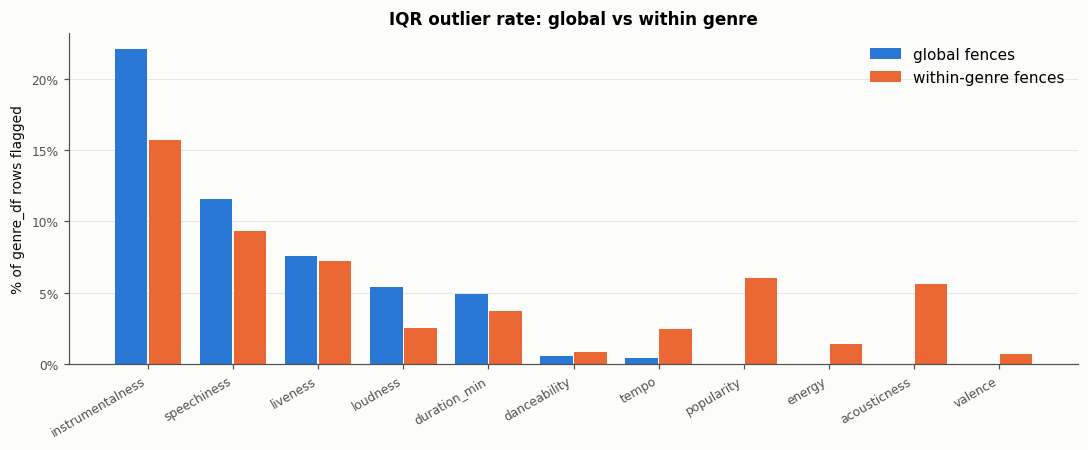

In [26]:
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

OUT_COLS = ["duration_min"] + AUDIO + ["popularity"]
rows = []
for col in OUT_COLS:
    s = genre_df[col]
    g_flag = iqr_flags(s) & s.notna()
    w_flag = genre_df.groupby("track_genre")[col].transform(iqr_flags) & s.notna()
    conc = genre_df.loc[g_flag, "track_genre"].value_counts()
    rows.append({
        "feature": col,
        "global_outlier_pct": 100 * iqr_flags(tracks[col].dropna()).mean(),
        "global_outlier_pct_genre_df": 100 * g_flag.mean(),
        "within_genre_outlier_pct": 100 * w_flag.mean(),
        "pct_of_global_outliers_still_outliers_in_own_genre": 100 * (g_flag & w_flag).sum() / max(g_flag.sum(), 1),
        "share_of_outliers_in_top5_genres": 100 * conc.head(5).sum() / max(conc.sum(), 1),
        "top_genres": ", ".join(f"{g} ({n})" for g, n in conc.head(4).items()),
    })
outlier_tbl = pd.DataFrame(rows).set_index("feature").sort_values("global_outlier_pct", ascending=False)
display(outlier_tbl.round(1))

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(outlier_tbl)); w = 0.38
ax.bar(x - w/2 - 0.01, outlier_tbl["global_outlier_pct_genre_df"], w, color=BLUE, label="global fences")
ax.bar(x + w/2 + 0.01, outlier_tbl["within_genre_outlier_pct"], w, color=ORANGE, label="within-genre fences")
ax.set_xticks(x); ax.set_xticklabels(outlier_tbl.index, rotation=30, ha="right")
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
ax.set_ylabel("% of genre_df rows flagged"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("IQR outlier rate: global vs within genre")
fig.tight_layout()
save_fig("14_outlier_rate_global_vs_genre")
plt.show()

In [27]:
# Duration extremes are the one place where "outlier" may mean "not a song": inspect them.
long_ = tracks[tracks["duration_min"] > 20]
short_ = tracks[tracks["duration_min"] < 0.5]
print(f"> 20 min: {len(long_)} tracks; genres: {long_['genres'].explode().value_counts().head(6).to_dict()}")
print(f"< 30 s:  {len(short_)} tracks; genres: {short_['genres'].explode().value_counts().head(6).to_dict()}")
display(long_.nlargest(5, "duration_min")[["track_name", "artists", "duration_min", "genres", "popularity"]].round(1))

> 20 min: 72 tracks; genres: {'classical': 13, 'iranian': 7, 'breakbeat': 7, 'sleep': 6, 'black-metal': 4, 'k-pop': 4}
< 30 s:  14 tracks; genres: {'iranian': 8, 'classical': 3, 'german': 2, 'british': 1, 'kids': 1, 'sleep': 1}


,track_name,artists,duration_min,genres,popularity
55302,Unity (Voyage Mix) Pt. 1,Tale Of Us,87.3,[minimal-techno],35
9207,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,79.8,[breakbeat],11
20474,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,78.8,[detroit-techno],8
55513,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,76.1,[minimal-techno],17
11389,House of Om - Mark Farina - Continuous Mix,Mark Farina,74.1,[chicago-house],11


**E6 findings and outlier decision**
* Under global IQR fences, `instrumentalness` (22%), `speechiness` (12%), `liveness` (8%), `loudness` (5%) and `duration` (5%) have the most flagged values. `energy`, `acousticness` and `valence` have none.
* **Most of these global outliers are normal inside their own genre.** Only 15% of loudness outliers and 27% of instrumentalness outliers are still outliers under within-genre fences. The rest are just quiet classical/ambient tracks, or instrumental electronic and classical tracks. Speechiness outliers come almost entirely from comedy.
* Removing them would delete whole genres (comedy, sleep, classical) and **bias the genre analysis**.
* **Decision: no rows are removed as outliers.** Instead:
  * use rank or log transforms (or tree models) for the skewed features
  * keep the `non_music` flag (145 sleep/white-noise tracks with no tempo)
  * for duration, note that tracks over 20 min (72) are DJ mixes or classical works and under 30 s (14) are interludes. They are real tracks, so cap/winsorise duration (e.g. at p99.5) for modelling rather than dropping them.
* Within-genre fences flag more `popularity` values (6%) than global fences do, because of the popularity-0 spikes inside some genres (E1, E4). This is the same sampling issue and does not call for outlier removal.